In [2]:
import requests
import pandas as pd
import time
from pathlib import Path

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

news_folder = (
    project_folder
    / "dataset"
    / "news_data"
)

news_folder.mkdir(
    parents=True,
    exist_ok=True
)

url = "https://api.gdeltproject.org/api/v2/doc/doc"

# Search a smaller period first
params = {
    "query": '"Reliance Industries"',
    "mode": "artlist",
    "maxrecords": 50,
    "format": "json",
    "startdatetime": "20250101000000",
    "enddatetime": "20250131000000",
    "sort": "datedesc"
}

print("Waiting before request...")
time.sleep(6)

try:
    response = requests.get(
        url,
        params=params,
        timeout=60
    )

    print("Status code:", response.status_code)

    if response.status_code == 200:

        data = response.json()

        articles = data.get("articles", [])

        print("Articles collected:", len(articles))

        if articles:

            rows = []

            for article in articles:
                rows.append({
                    "Date": article.get("seendate"),
                    "News": article.get("title"),
                    "URL": article.get("url"),
                    "Source": article.get("domain")
                })

            historical_news = pd.DataFrame(rows)

            # Convert GDELT date
            historical_news["Date"] = pd.to_datetime(
                historical_news["Date"],
                errors="coerce"
            ).dt.date

            # Remove missing titles
            historical_news = historical_news.dropna(
                subset=["News"]
            )

            output_file = (
                news_folder
                / "historical_news_test.csv"
            )

            historical_news.to_csv(
                output_file,
                index=False
            )

            print("\nNews dataset created!")
            print("Rows:", len(historical_news))
            print("Saved to:", output_file)

            print("\nFirst 5 articles:")
            display(historical_news.head())

        else:
            print("No articles returned.")

    elif response.status_code == 429:
        print("Still rate limited.")
        print("Wait 30–60 seconds before trying again.")

    else:
        print("Request failed.")
        print(response.text[:500])

except Exception as e:
    print("Error:", e)

Waiting before request...
Status code: 200
Articles collected: 50

News dataset created!
Rows: 50
Saved to: D:\Projects\StockMarketSentimentPrediction\dataset\news_data\historical_news_test.csv

First 5 articles:


,Date,News,URL,Source
0,2025-01-31,Blues owner secures bid to acquire Birmingham ...,https://www.thebusinessdesk.com/westmidlands/n...,thebusinessdesk.com
1,2025-01-31,Sector - Wise Budget Predictions for FY26,https://www.financialexpress.com/budget/sector...,financialexpress.com
2,2025-01-31,The art of self - regulation by crypto players...,https://www.rashtranews.com/the-art-of-self-re...,rashtranews.com
3,2025-01-31,Global environment benefits stock market,https://www.tarunbharat.com/global-environment...,tarunbharat.com
4,2025-01-31,What we already know about the world future la...,https://www.thestar.com.my/tech/tech-news/2025...,thestar.com.my


In [3]:
# Load the 50 collected articles
historical_news = pd.read_csv(
    r"D:\Projects\StockMarketSentimentPrediction\dataset\news_data\historical_news_test.csv"
)

# Make sure News is text
historical_news["News"] = (
    historical_news["News"]
    .fillna("")
    .astype(str)
)

# Keep articles that mention Reliance in the title
reliance_news = historical_news[
    historical_news["News"].str.contains(
        "Reliance",
        case=False,
        na=False
    )
].copy()

# Remove duplicate headlines
reliance_news = reliance_news.drop_duplicates(
    subset=["News"]
).reset_index(drop=True)

print("Original articles:", len(historical_news))
print("Reliance-related articles:", len(reliance_news))

print("\nFiltered articles:")
display(
    reliance_news[
        ["Date", "News", "Source"]
    ].head(20)
)

Original articles: 50
Reliance-related articles: 8

Filtered articles:


,Date,News,Source
0,2025-01-30,Stock markets extend gains for 3rd day ; Airte...,thehindu.com
1,2025-01-29,India Reliance Is Building Massive 3GW Data Ce...,datacenterknowledge.com
2,2025-01-29,Reliance Industries chairman Mukesh Ambani to ...,timesofindia.indiatimes.com
3,2025-01-29,Mukesh ambani reliance industries chairman app...,mymahanagar.com
4,2025-01-28,Mukesh Ambani lauds PM Modi vision for self - ...,aninews.in
5,2025-01-27,"Top 10 Indian Firms Shed Rs 94 , 409 Crore In ...",zeenews.india.com
6,2025-01-27,Mukesh Ambani Reliance to Build World Biggest ...,desiblitz.com
7,2025-01-27,"Top 10 Indian Firms Shed Rs 94 , 409 Crore In ...",menafn.com


In [5]:
import pandas as pd
from pathlib import Path

# Project path
project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

news_file = (
    project_folder
    / "dataset"
    / "news_data"
    / "historical_news_reliance.csv"
)

news_df = pd.read_csv(news_file)

print("Articles loaded:", len(news_df))
display(news_df[["Date", "News", "Source"]])

Articles loaded: 8


,Date,News,Source
0,2025-01-30,Stock markets extend gains for 3rd day ; Airte...,thehindu.com
1,2025-01-29,India Reliance Is Building Massive 3GW Data Ce...,datacenterknowledge.com
2,2025-01-29,Reliance Industries chairman Mukesh Ambani to ...,timesofindia.indiatimes.com
3,2025-01-29,Mukesh ambani reliance industries chairman app...,mymahanagar.com
4,2025-01-28,Mukesh Ambani lauds PM Modi vision for self - ...,aninews.in
5,2025-01-27,"Top 10 Indian Firms Shed Rs 94 , 409 Crore In ...",zeenews.india.com
6,2025-01-27,Mukesh Ambani Reliance to Build World Biggest ...,desiblitz.com
7,2025-01-27,"Top 10 Indian Firms Shed Rs 94 , 409 Crore In ...",menafn.com


In [6]:
from transformers import pipeline

print("Loading FinBERT...")

sentiment_model = pipeline(
    "sentiment-analysis",
    model="ProsusAI/finbert"
)

print("FinBERT loaded successfully!")

d:\Projects\StockMarketSentimentPrediction\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading FinBERT...


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 15355.36it/s]


FinBERT loaded successfully!


In [7]:
results = []

for index, row in news_df.iterrows():

    text = str(row["News"])

    result = sentiment_model(
        text,
        truncation=True,
        max_length=512
    )[0]

    results.append({
        "Date": row["Date"],
        "News": text,
        "Source": row["Source"],
        "Sentiment": result["label"],
        "Confidence": result["score"]
    })

sentiment_results = pd.DataFrame(results)

print("FinBERT analysis completed!")

display(sentiment_results)

FinBERT analysis completed!


,Date,News,Source,Sentiment,Confidence
0,2025-01-30,Stock markets extend gains for 3rd day ; Airte...,thehindu.com,positive,0.784747
1,2025-01-29,India Reliance Is Building Massive 3GW Data Ce...,datacenterknowledge.com,neutral,0.557786
2,2025-01-29,Reliance Industries chairman Mukesh Ambani to ...,timesofindia.indiatimes.com,neutral,0.899518
3,2025-01-29,Mukesh ambani reliance industries chairman app...,mymahanagar.com,neutral,0.859158
4,2025-01-28,Mukesh Ambani lauds PM Modi vision for self - ...,aninews.in,neutral,0.794065
5,2025-01-27,"Top 10 Indian Firms Shed Rs 94 , 409 Crore In ...",zeenews.india.com,negative,0.970465
6,2025-01-27,Mukesh Ambani Reliance to Build World Biggest ...,desiblitz.com,neutral,0.755582
7,2025-01-27,"Top 10 Indian Firms Shed Rs 94 , 409 Crore In ...",menafn.com,negative,0.968223


In [8]:
def convert_sentiment(row):
    label = row["Sentiment"].lower()
    confidence = row["Confidence"]

    if label == "positive":
        return confidence

    elif label == "negative":
        return -confidence

    else:
        return 0.0


sentiment_results["Sentiment_Score"] = (
    sentiment_results.apply(
        convert_sentiment,
        axis=1
    )
)

print("Numerical sentiment scores created!")

display(
    sentiment_results[
        [
            "Date",
            "Sentiment",
            "Confidence",
            "Sentiment_Score"
        ]
    ]
)

Numerical sentiment scores created!


,Date,Sentiment,Confidence,Sentiment_Score
0,2025-01-30,positive,0.784747,0.784747
1,2025-01-29,neutral,0.557786,0.000000
2,2025-01-29,neutral,0.899518,0.000000
3,2025-01-29,neutral,0.859158,0.000000
4,2025-01-28,neutral,0.794065,0.000000
5,2025-01-27,negative,0.970465,-0.970465
6,2025-01-27,neutral,0.755582,0.000000
7,2025-01-27,negative,0.968223,-0.968223


In [9]:
output_file = (
    project_folder
    / "dataset"
    / "news_data"
    / "historical_reliance_sentiment.csv"
)

sentiment_results.to_csv(
    output_file,
    index=False
)

print("================================")
print("FinBERT sentiment dataset saved!")
print("Articles:", len(sentiment_results))
print("Location:", output_file)
print("================================")

FinBERT sentiment dataset saved!
Articles: 8
Location: D:\Projects\StockMarketSentimentPrediction\dataset\news_data\historical_reliance_sentiment.csv


In [10]:
import pandas as pd
from pathlib import Path

# Project path
project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

# Load FinBERT results
sentiment_file = (
    project_folder
    / "dataset"
    / "news_data"
    / "historical_reliance_sentiment.csv"
)

sentiment_df = pd.read_csv(sentiment_file)

# Convert Date
sentiment_df["Date"] = pd.to_datetime(
    sentiment_df["Date"]
)

# ============================================
# Daily aggregation
# ============================================

daily_sentiment = (
    sentiment_df
    .groupby("Date")
    .agg(
        Daily_Sentiment=("Sentiment_Score", "mean"),
        News_Count=("Sentiment_Score", "count"),
        Average_Confidence=("Confidence", "mean")
    )
    .reset_index()
)

print("Daily sentiment records:",
      len(daily_sentiment))

print("\nDaily sentiment:")
display(daily_sentiment)

Daily sentiment records: 4

Daily sentiment:


,Date,Daily_Sentiment,News_Count,Average_Confidence
0,2025-01-27,-0.646229,3,0.898090
1,2025-01-28,0.000000,1,0.794065
2,2025-01-29,0.000000,3,0.772154
3,2025-01-30,0.784747,1,0.784747


In [11]:
output_file = (
    project_folder
    / "dataset"
    / "news_data"
    / "historical_daily_sentiment.csv"
)

daily_sentiment.to_csv(
    output_file,
    index=False
)

print("======================================")
print("Daily sentiment dataset saved!")
print("Records:", len(daily_sentiment))
print("Location:", output_file)
print("======================================")

Daily sentiment dataset saved!
Records: 4
Location: D:\Projects\StockMarketSentimentPrediction\dataset\news_data\historical_daily_sentiment.csv


In [2]:
import requests
import pandas as pd
import time
from pathlib import Path

# ============================================
# Project paths
# ============================================

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

news_folder = (
    project_folder
    / "dataset"
    / "news_data"
)

news_folder.mkdir(
    parents=True,
    exist_ok=True
)

# ============================================
# Function to collect one month
# ============================================

def collect_monthly_news(
    year,
    month,
    maxrecords=50
):

    start_date = f"{year}{month:02d}01000000"

    if month == 12:
        end_year = year + 1
        end_month = 1
    else:
        end_year = year
        end_month = month + 1

    end_date = f"{end_year}{end_month:02d}01000000"

    url = "https://api.gdeltproject.org/api/v2/doc/doc"

    params = {
        "query": '"Reliance Industries"',
        "mode": "artlist",
        "maxrecords": maxrecords,
        "format": "json",
        "startdatetime": start_date,
        "enddatetime": end_date,
        "sort": "datedesc"
    }

    print(
        f"Collecting {year}-{month:02d}..."
    )

    try:

        response = requests.get(
            url,
            params=params,
            timeout=60
        )

        print(
            "Status:",
            response.status_code
        )

        if response.status_code != 200:
            print(
                "Request failed."
            )
            return []

        data = response.json()

        articles = data.get(
            "articles",
            []
        )

        print(
            "Articles:",
            len(articles)
        )

        rows = []

        for article in articles:

            rows.append({
                "Date": article.get(
                    "seendate"
                ),
                "News": article.get(
                    "title"
                ),
                "URL": article.get(
                    "url"
                ),
                "Source": article.get(
                    "domain"
                )
            })

        return rows

    except Exception as e:

        print(
            "Error:",
            e
        )

        return []

In [3]:
import requests

def collect_monthly_news(year, month, maxrecords=50):

    if month == 12:
        end_year = year + 1
        end_month = 1
    else:
        end_year = year
        end_month = month + 1

    start_date = f"{year}{month:02d}01000000"
    end_date = f"{end_year}{end_month:02d}01000000"

    url = "https://api.gdeltproject.org/api/v2/doc/doc"

    params = {
        "query": '"Reliance Industries"',
        "mode": "artlist",
        "maxrecords": maxrecords,
        "format": "json",
        "startdatetime": start_date,
        "enddatetime": end_date,
        "sort": "datedesc"
    }

    print(f"Collecting {year}-{month:02d}...")

    response = requests.get(
        url,
        params=params,
        timeout=60
    )

    print("Status:", response.status_code)

    if response.status_code != 200:
        print("Request failed.")
        print(response.text[:300])
        return []

    data = response.json()

    articles = data.get("articles", [])

    print("Articles:", len(articles))

    rows = []

    for article in articles:
        rows.append({
            "Date": article.get("seendate"),
            "News": article.get("title"),
            "URL": article.get("url"),
            "Source": article.get("domain")
        })

    return rows


print("Function created successfully!")


Function created successfully!


In [5]:
import time

print("Waiting 6 seconds before requesting news...")
time.sleep(6)

february_news = collect_monthly_news(
    year=2025,
    month=2,
    maxrecords=50
)

print("\nTotal articles collected:", len(february_news))

Waiting 6 seconds before requesting news...
Status: 200
Articles: 50

Total articles collected: 50


In [6]:
from pathlib import Path
import pandas as pd

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

news_folder = (
    project_folder
    / "dataset"
    / "news_data"
)

february_df = pd.DataFrame(february_news)

february_df["Date"] = pd.to_datetime(
    february_df["Date"],
    errors="coerce"
)

february_file = (
    news_folder
    / "historical_news_2025_02.csv"
)

february_df.to_csv(
    february_file,
    index=False
)

print("February news saved!")
print("Rows:", len(february_df))
print("Location:", february_file)

February news saved!
Rows: 50
Location: D:\Projects\StockMarketSentimentPrediction\dataset\news_data\historical_news_2025_02.csv


In [7]:
january_file = (
    news_folder
    / "historical_news_test.csv"
)

january_df = pd.read_csv(
    january_file
)

february_df = pd.read_csv(
    february_file
)

all_news = pd.concat(
    [
        january_df,
        february_df
    ],
    ignore_index=True
)

# Remove duplicate URLs
all_news = all_news.drop_duplicates(
    subset=["URL"]
)

# Remove empty headlines
all_news = all_news.dropna(
    subset=["News"]
)

all_news = all_news.reset_index(
    drop=True
)

print("========== COMBINED NEWS ==========")
print("January articles:", len(january_df))
print("February articles:", len(february_df))
print("Combined unique articles:", len(all_news))

display(all_news.head(10))

========== COMBINED NEWS ==========
January articles: 50
February articles: 50
Combined unique articles: 100


,Date,News,URL,Source
0,2025-01-31,Blues owner secures bid to acquire Birmingham ...,https://www.thebusinessdesk.com/westmidlands/n...,thebusinessdesk.com
1,2025-01-31,Sector - Wise Budget Predictions for FY26,https://www.financialexpress.com/budget/sector...,financialexpress.com
2,2025-01-31,The art of self - regulation by crypto players...,https://www.rashtranews.com/the-art-of-self-re...,rashtranews.com
3,2025-01-31,Global environment benefits stock market,https://www.tarunbharat.com/global-environment...,tarunbharat.com
4,2025-01-31,What we already know about the world future la...,https://www.thestar.com.my/tech/tech-news/2025...,thestar.com.my
5,2025-01-31,Stocks to Watch : आज Laurus Labs और JBM Auto स...,https://navbharattimes.indiatimes.com/business...,navbharattimes.indiatimes.com
6,2025-01-30,Markets rally for third day on buying in blue ...,https://www.dailypioneer.com/2025/business/mar...,dailypioneer.com
7,2025-01-30,Mumbai Indians IPL owning Ambanis win race for...,https://www.cityam.com/mumbai-indians-ipl-owni...,cityam.com
8,2025-01-30,Ahead of Market : 10 things that will decide s...,https://economictimes.indiatimes.com/markets/s...,economictimes.indiatimes.com
9,2025-01-30,Sensex rises 227 points on buying in blue - ch...,https://www.rediff.com/business/report/sensex-...,rediff.com


In [8]:
keywords = [
    "reliance",
    "ril",
    "mukesh ambani",
    "jio",
    "reliance industries"
]

pattern = "|".join(keywords)

reliance_all_news = all_news[
    all_news["News"]
    .str.contains(
        pattern,
        case=False,
        na=False
    )
].copy()

reliance_all_news = (
    reliance_all_news
    .drop_duplicates(subset=["News"])
    .reset_index(drop=True)
)

print("========== FILTERED NEWS ==========")
print(
    "Reliance-related articles:",
    len(reliance_all_news)
)

display(
    reliance_all_news[
        ["Date", "News", "Source"]
    ].head(20)
)

========== FILTERED NEWS ==========
Reliance-related articles: 21


,Date,News,Source
0,2025-01-30,Stock markets extend gains for 3rd day ; Airte...,thehindu.com
1,2025-01-29,India Reliance Is Building Massive 3GW Data Ce...,datacenterknowledge.com
2,2025-01-29,Reliance Industries chairman Mukesh Ambani to ...,timesofindia.indiatimes.com
3,2025-01-29,Mukesh Ambani advises Gen Z to use khud ki bu...,financialexpress.com
4,2025-01-29,Mukesh ambani reliance industries chairman app...,mymahanagar.com
5,2025-01-29,Mukesh Ambani Shares 5 Valuable Life Lessons F...,idiva.com
6,2025-01-29,"Nayara , Jio - BP sell fuel on discount ; stat...",livemint.com
7,2025-01-28,Mukesh Ambani lauds PM Modi vision for self - ...,aninews.in
8,2025-01-28,India will become most prosperous nation in th...,moneycontrol.com
9,2025-01-28,Mukesh Ambani five guiding principle for stud...,moneycontrol.com


In [9]:
combined_file = (
    news_folder
    / "historical_reliance_news_2025_jan_feb.csv"
)

reliance_all_news.to_csv(
    combined_file,
    index=False
)

print("================================")
print("Combined Reliance news saved!")
print("Articles:", len(reliance_all_news))
print("Location:", combined_file)
print("================================")

Combined Reliance news saved!
Articles: 21
Location: D:\Projects\StockMarketSentimentPrediction\dataset\news_data\historical_reliance_news_2025_jan_feb.csv


In [10]:
import pandas as pd
from pathlib import Path

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

news_file = (
    project_folder
    / "dataset"
    / "news_data"
    / "historical_reliance_news_2025_jan_feb.csv"
)

news_df = pd.read_csv(news_file)

news_df["News"] = (
    news_df["News"]
    .fillna("")
    .astype(str)
)

print("Articles loaded:", len(news_df))

Articles loaded: 21


In [11]:
from transformers import pipeline

print("Loading FinBERT...")

sentiment_model = pipeline(
    "sentiment-analysis",
    model="ProsusAI/finbert"
)

print("FinBERT loaded successfully!")

d:\Projects\StockMarketSentimentPrediction\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading FinBERT...


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 30857.40it/s]


FinBERT loaded successfully!


In [12]:
results = []

for i, row in news_df.iterrows():

    text = str(row["News"])

    result = sentiment_model(
        text,
        truncation=True,
        max_length=512
    )[0]

    label = result["label"].lower()
    confidence = result["score"]

    if label == "positive":
        sentiment_score = confidence
    elif label == "negative":
        sentiment_score = -confidence
    else:
        sentiment_score = 0.0

    results.append({
        "Date": row["Date"],
        "News": text,
        "Source": row["Source"],
        "Sentiment": label,
        "Confidence": confidence,
        "Sentiment_Score": sentiment_score
    })

sentiment_results = pd.DataFrame(results)

print("================================")
print("FinBERT analysis completed!")
print("Articles analyzed:", len(sentiment_results))
print("================================")

display(sentiment_results.head(10))

FinBERT analysis completed!
Articles analyzed: 21


,Date,News,Source,Sentiment,Confidence,Sentiment_Score
0,2025-01-30,Stock markets extend gains for 3rd day ; Airte...,thehindu.com,positive,0.784747,0.784747
1,2025-01-29,India Reliance Is Building Massive 3GW Data Ce...,datacenterknowledge.com,neutral,0.557786,0.000000
2,2025-01-29,Reliance Industries chairman Mukesh Ambani to ...,timesofindia.indiatimes.com,neutral,0.899518,0.000000
3,2025-01-29,Mukesh Ambani advises Gen Z to use khud ki bu...,financialexpress.com,neutral,0.873594,0.000000
4,2025-01-29,Mukesh ambani reliance industries chairman app...,mymahanagar.com,neutral,0.859158,0.000000
5,2025-01-29,Mukesh Ambani Shares 5 Valuable Life Lessons F...,idiva.com,neutral,0.495518,0.000000
6,2025-01-29,"Nayara , Jio - BP sell fuel on discount ; stat...",livemint.com,negative,0.942145,-0.942145
7,2025-01-28,Mukesh Ambani lauds PM Modi vision for self - ...,aninews.in,neutral,0.794065,0.000000
8,2025-01-28,India will become most prosperous nation in th...,moneycontrol.com,positive,0.844891,0.844891
9,2025-01-28,Mukesh Ambani five guiding principle for stud...,moneycontrol.com,neutral,0.907101,0.000000


In [13]:
print("========== SENTIMENT DISTRIBUTION ==========")

print(
    sentiment_results["Sentiment"]
    .value_counts()
)

print("\n========== SENTIMENT STATISTICS ==========")

print(
    sentiment_results["Sentiment_Score"]
    .describe()
)

========== SENTIMENT DISTRIBUTION ==========
Sentiment
neutral     13
negative     5
positive     3
Name: count, dtype: int64

========== SENTIMENT STATISTICS ==========
count    21.000000
mean     -0.096422
std       0.512399
min      -0.970465
25%       0.000000
50%       0.000000
75%       0.000000
max       0.844891
Name: Sentiment_Score, dtype: float64


In [14]:
sentiment_output = (
    project_folder
    / "dataset"
    / "news_data"
    / "historical_reliance_sentiment_jan_feb.csv"
)

sentiment_results.to_csv(
    sentiment_output,
    index=False
)

print("======================================")
print("Expanded sentiment dataset saved!")
print("Articles:", len(sentiment_results))
print("Location:", sentiment_output)
print("======================================")

Expanded sentiment dataset saved!
Articles: 21
Location: D:\Projects\StockMarketSentimentPrediction\dataset\news_data\historical_reliance_sentiment_jan_feb.csv


In [16]:
import time

print("Waiting 6 seconds before requesting news...")
time.sleep(6)

march_news = collect_monthly_news(
    year=2025,
    month=3,
    maxrecords=50
)

print("\nTotal March articles:", len(march_news))

Waiting 6 seconds before requesting news...
Status: 200
Articles: 50

Total March articles: 50


In [17]:
march_df = pd.DataFrame(march_news)

march_df["Date"] = pd.to_datetime(
    march_df["Date"],
    errors="coerce"
)

march_file = (
    news_folder
    / "historical_news_2025_03.csv"
)

march_df.to_csv(
    march_file,
    index=False
)

print("March news saved!")
print("Rows:", len(march_df))

March news saved!
Rows: 50


In [ ]:
keywords = [
    "reliance",
    "ril",
    "mukesh ambani",
    "jio",
    "reliance industries"
]

pattern = "|".join(keywords)

reliance_all_news = all_news[
    all_news["News"].str.contains(
        pattern,
        case=False,
        na=False
    )
].copy()

reliance_all_news = (
    reliance_all_news
    .drop_duplicates(subset=["News"])
    .reset_index(drop=True)
)

print(
    "Reliance-related articles:",
    len(reliance_all_news)
)

Reliance-related articles: 21


In [2]:
import requests
import time
import pandas as pd
from pathlib import Path

# ============================================
# PROJECT PATHS
# ============================================

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

news_folder = (
    project_folder
    / "dataset"
    / "news_data"
)

news_folder.mkdir(
    parents=True,
    exist_ok=True
)

# ============================================
# MONTHLY NEWS COLLECTION FUNCTION
# ============================================

def collect_monthly_news(year, month, maxrecords=50):

    if month == 12:
        end_year = year + 1
        end_month = 1
    else:
        end_year = year
        end_month = month + 1

    start_date = (
        f"{year}{month:02d}01000000"
    )

    end_date = (
        f"{end_year}{end_month:02d}01000000"
    )

    url = (
        "https://api.gdeltproject.org/api/v2/doc/doc"
    )

    params = {
        "query": '"Reliance Industries"',
        "mode": "artlist",
        "maxrecords": maxrecords,
        "format": "json",
        "startdatetime": start_date,
        "enddatetime": end_date,
        "sort": "datedesc"
    }

    print(
        f"Collecting {year}-{month:02d}..."
    )

    try:

        response = requests.get(
            url,
            params=params,
            timeout=60
        )

        print(
            "Status:",
            response.status_code
        )

        if response.status_code != 200:

            print(
                "Request failed."
            )

            return []

        data = response.json()

        articles = data.get(
            "articles",
            []
        )

        print(
            "Articles:",
            len(articles)
        )

        rows = []

        for article in articles:

            rows.append({
                "Date": article.get(
                    "seendate"
                ),
                "News": article.get(
                    "title"
                ),
                "URL": article.get(
                    "url"
                ),
                "Source": article.get(
                    "domain"
                )
            })

        return rows

    except Exception as e:

        print(
            "Error:",
            e
        )

        return []


print("================================")
print("News collection function ready!")
print("================================")

News collection function ready!


In [4]:
print("Waiting 6 seconds...")
time.sleep(6)

april_news = collect_monthly_news(
    year=2025,
    month=4,
    maxrecords=50
)

print(
    "\nTotal April articles:",
    len(april_news)
)

Waiting 6 seconds...
Status: 200
Articles: 50

Total April articles: 50


In [5]:
april_df = pd.DataFrame(
    april_news
)

april_df["Date"] = pd.to_datetime(
    april_df["Date"],
    errors="coerce"
)

april_file = (
    news_folder
    / "historical_news_2025_04.csv"
)

april_df.to_csv(
    april_file,
    index=False
)

print(
    "April news saved!"
)

print(
    "Rows:",
    len(april_df)
)

# ============================================
# FILTER RELIANCE NEWS
# ============================================

keywords = [
    "reliance",
    "ril",
    "mukesh ambani",
    "jio",
    "reliance industries"
]

pattern = "|".join(keywords)

april_reliance = april_df[
    april_df["News"]
    .fillna("")
    .str.contains(
        pattern,
        case=False,
        na=False
    )
].copy()

april_reliance = (
    april_reliance
    .drop_duplicates(
        subset=["News"]
    )
    .reset_index(drop=True)
)

print(
    "\nApril Reliance-related articles:",
    len(april_reliance)
)

April news saved!
Rows: 50

April Reliance-related articles: 21


In [6]:
print("Waiting 6 seconds...")
time.sleep(6)

may_news = collect_monthly_news(
    year=2025,
    month=5,
    maxrecords=50
)

print(
    "\nTotal May articles:",
    len(may_news)
)

Waiting 6 seconds...
Status: 200
Articles: 50

Total May articles: 50


In [7]:
may_df = pd.DataFrame(may_news)

may_df["Date"] = pd.to_datetime(
    may_df["Date"],
    errors="coerce"
)

may_file = (
    news_folder
    / "historical_news_2025_05.csv"
)

may_df.to_csv(
    may_file,
    index=False
)

keywords = [
    "reliance",
    "ril",
    "mukesh ambani",
    "jio",
    "reliance industries"
]

pattern = "|".join(keywords)

may_reliance = may_df[
    may_df["News"]
    .fillna("")
    .str.contains(
        pattern,
        case=False,
        na=False
    )
].copy()

may_reliance = (
    may_reliance
    .drop_duplicates(subset=["News"])
    .reset_index(drop=True)
)

print("May news saved!")
print("Raw articles:", len(may_df))
print(
    "May Reliance-related articles:",
    len(may_reliance)
)

May news saved!
Raw articles: 50
May Reliance-related articles: 11


In [8]:
import time
import pandas as pd

print("Waiting 6 seconds...")
time.sleep(6)

# Collect May 2025 news
may_news = collect_monthly_news(
    year=2025,
    month=5,
    maxrecords=50
)

print("\nTotal May articles:", len(may_news))

# Convert to DataFrame
may_df = pd.DataFrame(may_news)

if len(may_df) > 0:

    may_df["Date"] = pd.to_datetime(
        may_df["Date"],
        errors="coerce"
    )

    # Save raw May news
    may_file = (
        news_folder
        / "historical_news_2025_05.csv"
    )

    may_df.to_csv(
        may_file,
        index=False
    )

    # ============================================
    # Filter Reliance-related articles
    # ============================================

    keywords = [
        "reliance",
        "ril",
        "mukesh ambani",
        "jio",
        "reliance industries"
    ]

    pattern = "|".join(keywords)

    may_reliance = may_df[
        may_df["News"]
        .fillna("")
        .str.contains(
            pattern,
            case=False,
            na=False
        )
    ].copy()

    may_reliance = (
        may_reliance
        .drop_duplicates(
            subset=["News"]
        )
        .reset_index(drop=True)
    )

    print("\n========== MAY 2025 ==========")
    print("Raw articles:", len(may_df))
    print(
        "Reliance-related articles:",
        len(may_reliance)
    )

    print("\nFirst 10 filtered articles:")
    display(
        may_reliance[
            ["Date", "News", "Source"]
        ].head(10)
    )

else:
    print("No May articles returned.")

Waiting 6 seconds...
Status: 200
Articles: 50

Total May articles: 50

========== MAY 2025 ==========
Raw articles: 50
Reliance-related articles: 11

First 10 filtered articles:


,Date,News,Source
0,2025-06-01 10:30:00+00:00,Reliance launches Campa Cola in Bahrain with B...,tradearabia.com
1,2025-05-30 18:00:00+00:00,Reliance Jio Infocomm seeks 26 GHz Wi - Fi app...,rcrwireless.com
2,2025-05-30 16:45:00+00:00,"New CVB launches in Mahrashtra , India – celeb...",c-mw.net
3,2025-05-29 09:45:00+00:00,"Reliance Industries Update , अंबानी की नजर अब ...",navbharattimes.indiatimes.com
4,2025-05-29 06:30:00+00:00,"JioBlackRock AMC to widen reach , target flows...",thehindubusinessline.com
5,2025-05-29 06:30:00+00:00,"BP Castrol unit draws interest from Reliance ,...",thehindubusinessline.com
6,2025-05-29 06:30:00+00:00,"BP Castrol Unit Gets Interest from Reliance , ...",marketscreener.com
7,2025-05-29 06:00:00+00:00,Mukesh Ambani and Anil Ambani lesser - known y...,dnaindia.com
8,2025-05-29 06:00:00+00:00,"Mukesh Ambani , Isha Ambani brought these 5 gl...",india.com
9,2025-05-29 05:30:00+00:00,Castrol India shares rise 7 % on report Relian...,businesstoday.in


In [4]:
import requests
import time
import pandas as pd
from pathlib import Path

# ============================================
# PROJECT PATH
# ============================================

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

news_folder = (
    project_folder
    / "dataset"
    / "news_data"
)

news_folder.mkdir(
    parents=True,
    exist_ok=True
)

# ============================================
# NEWS COLLECTION FUNCTION
# ============================================

def collect_monthly_news(year, month, maxrecords=50):

    if month == 12:
        end_year = year + 1
        end_month = 1
    else:
        end_year = year
        end_month = month + 1

    start_date = f"{year}{month:02d}01000000"
    end_date = f"{end_year}{end_month:02d}01000000"

    url = "https://api.gdeltproject.org/api/v2/doc/doc"

    params = {
        "query": '"Reliance Industries"',
        "mode": "artlist",
        "maxrecords": maxrecords,
        "format": "json",
        "startdatetime": start_date,
        "enddatetime": end_date,
        "sort": "datedesc"
    }

    print(f"Collecting {year}-{month:02d}...")

    try:

        response = requests.get(
            url,
            params=params,
            timeout=60
        )

        print("Status:", response.status_code)

        if response.status_code != 200:
            print("Request failed.")
            return []

        data = response.json()

        articles = data.get(
            "articles",
            []
        )

        print("Articles:", len(articles))

        rows = []

        for article in articles:

            rows.append({
                "Date": article.get("seendate"),
                "News": article.get("title"),
                "URL": article.get("url"),
                "Source": article.get("domain")
            })

        return rows

    except Exception as e:

        print("Error:", e)
        return []


# ============================================
# COLLECT JUNE 2025
# ============================================

print("Waiting 6 seconds...")
time.sleep(6)

june_news = collect_monthly_news(
    year=2025,
    month=6,
    maxrecords=50
)

print("\nTotal June articles:", len(june_news))


# ============================================
# SAVE JUNE NEWS
# ============================================

june_df = pd.DataFrame(june_news)

if len(june_df) > 0:

    june_df["Date"] = pd.to_datetime(
        june_df["Date"],
        errors="coerce"
    )

    june_file = (
        news_folder
        / "historical_news_2025_06.csv"
    )

    june_df.to_csv(
        june_file,
        index=False
    )

    # ========================================
    # FILTER RELIANCE-RELATED NEWS
    # ========================================

    keywords = [
        "reliance",
        "ril",
        "mukesh ambani",
        "jio",
        "reliance industries"
    ]

    pattern = "|".join(keywords)

    june_reliance = june_df[
        june_df["News"]
        .fillna("")
        .str.contains(
            pattern,
            case=False,
            na=False
        )
    ].copy()

    june_reliance = (
        june_reliance
        .drop_duplicates(
            subset=["News"]
        )
        .reset_index(drop=True)
    )

    print("\n========== JUNE 2025 ==========")
    print("Raw articles:", len(june_df))
    print(
        "Reliance-related articles:",
        len(june_reliance)
    )

    print("\nJune news saved to:")
    print(june_file)

else:

    print("No June articles returned.")

Waiting 6 seconds...
Status: 200
Articles: 50

Total June articles: 50

========== JUNE 2025 ==========
Raw articles: 50
Reliance-related articles: 21

June news saved to:
D:\Projects\StockMarketSentimentPrediction\dataset\news_data\historical_news_2025_06.csv


In [2]:
import requests
import time
import pandas as pd
from pathlib import Path

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

news_folder = project_folder / "dataset" / "news_data"
news_folder.mkdir(parents=True, exist_ok=True)


def collect_monthly_news(year, month, maxrecords=50):

    if month == 12:
        end_year = year + 1
        end_month = 1
    else:
        end_year = year
        end_month = month + 1

    start_date = f"{year}{month:02d}01000000"
    end_date = f"{end_year}{end_month:02d}01000000"

    url = "https://api.gdeltproject.org/api/v2/doc/doc"

    params = {
        "query": '"Reliance Industries"',
        "mode": "artlist",
        "maxrecords": maxrecords,
        "format": "json",
        "startdatetime": start_date,
        "enddatetime": end_date,
        "sort": "datedesc"
    }

    print(f"Collecting {year}-{month:02d}...")

    response = requests.get(
        url,
        params=params,
        timeout=60
    )

    print("Status:", response.status_code)

    if response.status_code != 200:
        print("Request failed.")
        return []

    articles = response.json().get("articles", [])

    print("Articles:", len(articles))

    return [
        {
            "Date": article.get("seendate"),
            "News": article.get("title"),
            "URL": article.get("url"),
            "Source": article.get("domain")
        }
        for article in articles
    ]


# ============================================
# JULY 2025
# ============================================

print("Waiting 6 seconds...")
time.sleep(6)

july_news = collect_monthly_news(
    2025,
    7,
    50
)

print("\nTotal July articles:", len(july_news))


# ============================================
# SAVE JULY
# ============================================

july_df = pd.DataFrame(july_news)

if len(july_df) > 0:

    july_df["Date"] = pd.to_datetime(
        july_df["Date"],
        errors="coerce"
    )

    july_file = (
        news_folder /
        "historical_news_2025_07.csv"
    )

    july_df.to_csv(
        july_file,
        index=False
    )

    # Filter relevant news
    keywords = [
        "reliance",
        "ril",
        "mukesh ambani",
        "jio",
        "reliance industries"
    ]

    pattern = "|".join(keywords)

    july_reliance = july_df[
        july_df["News"]
        .fillna("")
        .str.contains(
            pattern,
            case=False,
            na=False
        )
    ].drop_duplicates(
        subset=["News"]
    ).reset_index(drop=True)

    print("\n========== JULY 2025 ==========")
    print("Raw articles:", len(july_df))
    print(
        "Reliance-related articles:",
        len(july_reliance)
    )
    print("Saved to:", july_file)

else:
    print("No July articles returned.")

Waiting 6 seconds...
Status: 200
Articles: 50

Total July articles: 50

========== JULY 2025 ==========
Raw articles: 50
Reliance-related articles: 9
Saved to: D:\Projects\StockMarketSentimentPrediction\dataset\news_data\historical_news_2025_07.csv


In [3]:
import requests
import time
import pandas as pd
from pathlib import Path

# ============================================
# PROJECT PATH
# ============================================

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

news_folder = (
    project_folder / "dataset" / "news_data"
)

news_folder.mkdir(
    parents=True,
    exist_ok=True
)

# ============================================
# FUNCTION
# ============================================

def collect_monthly_news(
    year,
    month,
    maxrecords=50
):

    if month == 12:
        end_year = year + 1
        end_month = 1
    else:
        end_year = year
        end_month = month + 1

    start_date = (
        f"{year}{month:02d}01000000"
    )

    end_date = (
        f"{end_year}{end_month:02d}01000000"
    )

    url = (
        "https://api.gdeltproject.org/api/v2/doc/doc"
    )

    params = {
        "query": '"Reliance Industries"',
        "mode": "artlist",
        "maxrecords": maxrecords,
        "format": "json",
        "startdatetime": start_date,
        "enddatetime": end_date,
        "sort": "datedesc"
    }

    print(
        f"Collecting {year}-{month:02d}..."
    )

    try:

        response = requests.get(
            url,
            params=params,
            timeout=60
        )

        print(
            "Status:",
            response.status_code
        )

        if response.status_code != 200:
            print(
                "Request failed."
            )
            return []

        articles = response.json().get(
            "articles",
            []
        )

        print(
            "Articles:",
            len(articles)
        )

        rows = []

        for article in articles:

            rows.append({
                "Date": article.get(
                    "seendate"
                ),
                "News": article.get(
                    "title"
                ),
                "URL": article.get(
                    "url"
                ),
                "Source": article.get(
                    "domain"
                )
            })

        return rows

    except Exception as e:

        print(
            "Error:",
            e
        )

        return []


# ============================================
# COLLECT AUGUST 2025
# ============================================

print(
    "Waiting 6 seconds..."
)

time.sleep(6)

august_news = collect_monthly_news(
    2025,
    8,
    50
)

print(
    "\nTotal August articles:",
    len(august_news)
)


# ============================================
# SAVE
# ============================================

august_df = pd.DataFrame(
    august_news
)

if len(august_df) > 0:

    august_df["Date"] = pd.to_datetime(
        august_df["Date"],
        errors="coerce"
    )

    august_file = (
        news_folder
        / "historical_news_2025_08.csv"
    )

    august_df.to_csv(
        august_file,
        index=False
    )

    # ========================================
    # FILTER
    # ========================================

    keywords = [
        "reliance",
        "ril",
        "mukesh ambani",
        "jio",
        "reliance industries"
    ]

    pattern = "|".join(
        keywords
    )

    august_reliance = august_df[
        august_df["News"]
        .fillna("")
        .str.contains(
            pattern,
            case=False,
            na=False
        )
    ].drop_duplicates(
        subset=["News"]
    ).reset_index(
        drop=True
    )

    print(
        "\n========== AUGUST 2025 =========="
    )

    print(
        "Raw articles:",
        len(august_df)
    )

    print(
        "Reliance-related articles:",
        len(august_reliance)
    )

    print(
        "Saved to:",
        august_file
    )

else:

    print(
        "No August articles returned."
    )

Waiting 6 seconds...
Status: 200
Articles: 50

Total August articles: 50

========== AUGUST 2025 ==========
Raw articles: 50
Reliance-related articles: 22
Saved to: D:\Projects\StockMarketSentimentPrediction\dataset\news_data\historical_news_2025_08.csv


In [5]:
import requests
import time
import pandas as pd
from pathlib import Path

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

news_folder = (
    project_folder / "dataset" / "news_data"
)

news_folder.mkdir(
    parents=True,
    exist_ok=True
)


def collect_monthly_news(year, month, maxrecords=50):

    if month == 12:
        end_year = year + 1
        end_month = 1
    else:
        end_year = year
        end_month = month + 1

    start_date = f"{year}{month:02d}01000000"
    end_date = f"{end_year}{end_month:02d}01000000"

    url = "https://api.gdeltproject.org/api/v2/doc/doc"

    params = {
        "query": '"Reliance Industries"',
        "mode": "artlist",
        "maxrecords": maxrecords,
        "format": "json",
        "startdatetime": start_date,
        "enddatetime": end_date,
        "sort": "datedesc"
    }

    print(f"Collecting {year}-{month:02d}...")

    try:

        response = requests.get(
            url,
            params=params,
            timeout=60
        )

        print("Status:", response.status_code)

        if response.status_code != 200:
            print("Request failed.")
            return []

        articles = response.json().get(
            "articles",
            []
        )

        print("Articles:", len(articles))

        return [
            {
                "Date": article.get("seendate"),
                "News": article.get("title"),
                "URL": article.get("url"),
                "Source": article.get("domain")
            }
            for article in articles
        ]

    except Exception as e:

        print("Error:", e)
        return []


# ============================================
# SEPTEMBER 2025
# ============================================

print("Waiting 6 seconds...")
time.sleep(6)

september_news = collect_monthly_news(
    2025,
    9,
    50
)

print(
    "\nTotal September articles:",
    len(september_news)
)


# ============================================
# SAVE
# ============================================

september_df = pd.DataFrame(
    september_news
)

if len(september_df) > 0:

    september_df["Date"] = pd.to_datetime(
        september_df["Date"],
        errors="coerce"
    )

    september_file = (
        news_folder /
        "historical_news_2025_09.csv"
    )

    september_df.to_csv(
        september_file,
        index=False
    )

    # ========================================
    # FILTER
    # ========================================

    keywords = [
        "reliance",
        "ril",
        "mukesh ambani",
        "jio",
        "reliance industries"
    ]

    pattern = "|".join(keywords)

    september_reliance = september_df[
        september_df["News"]
        .fillna("")
        .str.contains(
            pattern,
            case=False,
            na=False
        )
    ].drop_duplicates(
        subset=["News"]
    ).reset_index(drop=True)

    print(
        "\n========== SEPTEMBER 2025 =========="
    )

    print(
        "Raw articles:",
        len(september_df)
    )

    print(
        "Reliance-related articles:",
        len(september_reliance)
    )

    print(
        "Saved to:",
        september_file
    )

else:

    print("No September articles returned.")

Waiting 6 seconds...
Status: 200
Articles: 50

Total September articles: 50

========== SEPTEMBER 2025 ==========
Raw articles: 50
Reliance-related articles: 14
Saved to: D:\Projects\StockMarketSentimentPrediction\dataset\news_data\historical_news_2025_09.csv


In [7]:
import requests
import time
import pandas as pd
from pathlib import Path

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

news_folder = (
    project_folder / "dataset" / "news_data"
)

news_folder.mkdir(
    parents=True,
    exist_ok=True
)


def collect_monthly_news(year, month, maxrecords=50):

    if month == 12:
        end_year = year + 1
        end_month = 1
    else:
        end_year = year
        end_month = month + 1

    start_date = f"{year}{month:02d}01000000"
    end_date = f"{end_year}{end_month:02d}01000000"

    url = "https://api.gdeltproject.org/api/v2/doc/doc"

    params = {
        "query": '"Reliance Industries"',
        "mode": "artlist",
        "maxrecords": maxrecords,
        "format": "json",
        "startdatetime": start_date,
        "enddatetime": end_date,
        "sort": "datedesc"
    }

    print(f"Collecting {year}-{month:02d}...")

    try:
        response = requests.get(
            url,
            params=params,
            timeout=60
        )

        print("Status:", response.status_code)

        if response.status_code != 200:
            print("Request failed.")
            return []

        articles = response.json().get(
            "articles", []
        )

        print("Articles:", len(articles))

        return [
            {
                "Date": article.get("seendate"),
                "News": article.get("title"),
                "URL": article.get("url"),
                "Source": article.get("domain")
            }
            for article in articles
        ]

    except Exception as e:
        print("Error:", e)
        return []


print("Waiting 6 seconds...")
time.sleep(6)

october_news = collect_monthly_news(
    2025,
    10,
    50
)

print(
    "\nTotal October articles:",
    len(october_news)
)

october_df = pd.DataFrame(
    october_news
)

if len(october_df) > 0:

    october_df["Date"] = pd.to_datetime(
        october_df["Date"],
        errors="coerce"
    )

    october_file = (
        news_folder /
        "historical_news_2025_10.csv"
    )

    october_df.to_csv(
        october_file,
        index=False
    )

    keywords = [
        "reliance",
        "ril",
        "mukesh ambani",
        "jio",
        "reliance industries"
    ]

    pattern = "|".join(keywords)

    october_reliance = october_df[
        october_df["News"]
        .fillna("")
        .str.contains(
            pattern,
            case=False,
            na=False
        )
    ].drop_duplicates(
        subset=["News"]
    ).reset_index(drop=True)

    print(
        "\n========== OCTOBER 2025 =========="
    )
    print(
        "Raw articles:",
        len(october_df)
    )
    print(
        "Reliance-related articles:",
        len(october_reliance)
    )
    print(
        "Saved to:",
        october_file
    )

else:
    print("No October articles returned.")

Waiting 6 seconds...
Status: 200
Articles: 50

Total October articles: 50

========== OCTOBER 2025 ==========
Raw articles: 50
Reliance-related articles: 19
Saved to: D:\Projects\StockMarketSentimentPrediction\dataset\news_data\historical_news_2025_10.csv


In [8]:
import requests
import time
import pandas as pd
from pathlib import Path

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

news_folder = (
    project_folder / "dataset" / "news_data"
)

news_folder.mkdir(
    parents=True,
    exist_ok=True
)


def collect_monthly_news(year, month, maxrecords=50):

    if month == 12:
        end_year = year + 1
        end_month = 1
    else:
        end_year = year
        end_month = month + 1

    start_date = f"{year}{month:02d}01000000"
    end_date = f"{end_year}{end_month:02d}01000000"

    url = "https://api.gdeltproject.org/api/v2/doc/doc"

    params = {
        "query": '"Reliance Industries"',
        "mode": "artlist",
        "maxrecords": maxrecords,
        "format": "json",
        "startdatetime": start_date,
        "enddatetime": end_date,
        "sort": "datedesc"
    }

    print(f"Collecting {year}-{month:02d}...")

    try:
        response = requests.get(
            url,
            params=params,
            timeout=60
        )

        print("Status:", response.status_code)

        if response.status_code != 200:
            print("Request failed.")
            return []

        articles = response.json().get(
            "articles", []
        )

        print("Articles:", len(articles))

        return [
            {
                "Date": article.get("seendate"),
                "News": article.get("title"),
                "URL": article.get("url"),
                "Source": article.get("domain")
            }
            for article in articles
        ]

    except Exception as e:
        print("Error:", e)
        return []


print("Waiting 6 seconds...")
time.sleep(6)

november_news = collect_monthly_news(
    2025,
    11,
    50
)

print(
    "\nTotal November articles:",
    len(november_news)
)

november_df = pd.DataFrame(november_news)

if len(november_df) > 0:

    november_df["Date"] = pd.to_datetime(
        november_df["Date"],
        errors="coerce"
    )

    november_file = (
        news_folder /
        "historical_news_2025_11.csv"
    )

    november_df.to_csv(
        november_file,
        index=False
    )

    keywords = [
        "reliance",
        "ril",
        "mukesh ambani",
        "jio",
        "reliance industries"
    ]

    pattern = "|".join(keywords)

    november_reliance = november_df[
        november_df["News"]
        .fillna("")
        .str.contains(
            pattern,
            case=False,
            na=False
        )
    ].drop_duplicates(
        subset=["News"]
    ).reset_index(drop=True)

    print(
        "\n========== NOVEMBER 2025 =========="
    )
    print(
        "Raw articles:",
        len(november_df)
    )
    print(
        "Reliance-related articles:",
        len(november_reliance)
    )
    print(
        "Saved to:",
        november_file
    )

else:
    print("No November articles returned.")

Waiting 6 seconds...
Status: 200
Articles: 50

Total November articles: 50

========== NOVEMBER 2025 ==========
Raw articles: 50
Reliance-related articles: 18
Saved to: D:\Projects\StockMarketSentimentPrediction\dataset\news_data\historical_news_2025_11.csv


In [9]:
import requests
import time
import pandas as pd
from pathlib import Path

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

news_folder = (
    project_folder / "dataset" / "news_data"
)

news_folder.mkdir(
    parents=True,
    exist_ok=True
)


def collect_monthly_news(year, month, maxrecords=50):

    if month == 12:
        end_year = year + 1
        end_month = 1
    else:
        end_year = year
        end_month = month + 1

    start_date = f"{year}{month:02d}01000000"
    end_date = f"{end_year}{end_month:02d}01000000"

    url = "https://api.gdeltproject.org/api/v2/doc/doc"

    params = {
        "query": '"Reliance Industries"',
        "mode": "artlist",
        "maxrecords": maxrecords,
        "format": "json",
        "startdatetime": start_date,
        "enddatetime": end_date,
        "sort": "datedesc"
    }

    print(f"Collecting {year}-{month:02d}...")

    try:

        response = requests.get(
            url,
            params=params,
            timeout=60
        )

        print("Status:", response.status_code)

        if response.status_code != 200:
            print("Request failed.")
            return []

        articles = response.json().get(
            "articles", []
        )

        print("Articles:", len(articles))

        return [
            {
                "Date": article.get("seendate"),
                "News": article.get("title"),
                "URL": article.get("url"),
                "Source": article.get("domain")
            }
            for article in articles
        ]

    except Exception as e:

        print("Error:", e)
        return []


# ============================================
# DECEMBER 2025
# ============================================

print("Waiting 6 seconds...")
time.sleep(6)

december_news = collect_monthly_news(
    2025,
    12,
    50
)

print(
    "\nTotal December articles:",
    len(december_news)
)


# ============================================
# SAVE
# ============================================

december_df = pd.DataFrame(
    december_news
)

if len(december_df) > 0:

    december_df["Date"] = pd.to_datetime(
        december_df["Date"],
        errors="coerce"
    )

    december_file = (
        news_folder /
        "historical_news_2025_12.csv"
    )

    december_df.to_csv(
        december_file,
        index=False
    )

    # ========================================
    # FILTER RELIANCE NEWS
    # ========================================

    keywords = [
        "reliance",
        "ril",
        "mukesh ambani",
        "jio",
        "reliance industries"
    ]

    pattern = "|".join(keywords)

    december_reliance = december_df[
        december_df["News"]
        .fillna("")
        .str.contains(
            pattern,
            case=False,
            na=False
        )
    ].drop_duplicates(
        subset=["News"]
    ).reset_index(drop=True)

    print(
        "\n========== DECEMBER 2025 =========="
    )

    print(
        "Raw articles:",
        len(december_df)
    )

    print(
        "Reliance-related articles:",
        len(december_reliance)
    )

    print(
        "Saved to:",
        december_file
    )

else:

    print(
        "No December articles returned."
    )

Waiting 6 seconds...
Status: 200
Articles: 50

Total December articles: 50

========== DECEMBER 2025 ==========
Raw articles: 50
Reliance-related articles: 6
Saved to: D:\Projects\StockMarketSentimentPrediction\dataset\news_data\historical_news_2025_12.csv


In [10]:
import pandas as pd
from pathlib import Path

# ============================================
# PROJECT PATH
# ============================================

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

news_folder = (
    project_folder
    / "dataset"
    / "news_data"
)

# ============================================
# LOAD ALL 2025 MONTHLY FILES
# ============================================

monthly_files = sorted(
    news_folder.glob(
        "historical_news_2025_*.csv"
    )
)

print(
    "Monthly files found:",
    len(monthly_files)
)

all_news = []

for file in monthly_files:

    temp = pd.read_csv(file)

    print(
        file.name,
        "->",
        len(temp),
        "articles"
    )

    all_news.append(temp)


# ============================================
# COMBINE
# ============================================

combined_news = pd.concat(
    all_news,
    ignore_index=True
)

print("\n========== COMBINED NEWS ==========")
print(
    "Total articles:",
    len(combined_news)
)

# ============================================
# CLEAN
# ============================================

combined_news["News"] = (
    combined_news["News"]
    .fillna("")
    .astype(str)
    .str.strip()
)

combined_news["Date"] = pd.to_datetime(
    combined_news["Date"],
    errors="coerce"
)

# Remove empty headlines
combined_news = combined_news[
    combined_news["News"] != ""
].copy()

# Remove duplicate headlines
before = len(combined_news)

combined_news = (
    combined_news
    .drop_duplicates(
        subset=["News"]
    )
    .reset_index(drop=True)
)

after = len(combined_news)

print(
    "Duplicates removed:",
    before - after
)

print(
    "Final unique articles:",
    len(combined_news)
)

# ============================================
# SAVE COMBINED FILE
# ============================================

combined_file = (
    news_folder
    / "historical_reliance_news_2025_all.csv"
)

combined_news.to_csv(
    combined_file,
    index=False
)

print(
    "\nCombined news saved to:"
)

print(combined_file)

print("\nFirst 5 articles:")

display(
    combined_news[
        ["Date", "News", "Source"]
    ].head()
)

Monthly files found: 11
historical_news_2025_02.csv -> 50 articles
historical_news_2025_03.csv -> 50 articles
historical_news_2025_04.csv -> 50 articles
historical_news_2025_05.csv -> 50 articles
historical_news_2025_06.csv -> 50 articles
historical_news_2025_07.csv -> 50 articles
historical_news_2025_08.csv -> 50 articles
historical_news_2025_09.csv -> 50 articles
historical_news_2025_10.csv -> 50 articles
historical_news_2025_11.csv -> 50 articles
historical_news_2025_12.csv -> 50 articles

========== COMBINED NEWS ==========
Total articles: 550
Duplicates removed: 25
Final unique articles: 525

Combined news saved to:
D:\Projects\StockMarketSentimentPrediction\dataset\news_data\historical_reliance_news_2025_all.csv

First 5 articles:


,Date,News,Source
0,2025-03-01 23:30:00+00:00,Elon Musk has lost more money in just 2 months...,india.com
1,2025-03-01 03:00:00+00:00,Equity Mutual Funds With Highest Returns Amid ...,financialexpress.com
2,2025-02-28 18:45:00+00:00,Extremely high uncertainty for Niagara real e...,stcatharinesstandard.ca
3,2025-02-28 14:00:00+00:00,Strand Life Sciences Launches Portal to Help D...,bilkulonline.com
4,2025-02-28 12:00:00+00:00,Assam will be in next league of development if...,news.webindia123.com


In [11]:
from pathlib import Path
import pandas as pd

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

news_folder = (
    project_folder
    / "dataset"
    / "news_data"
)

print("Checking January files...\n")

for file in news_folder.glob("*2025*01*.csv"):
    print(file.name)
    print("Rows:", len(pd.read_csv(file)))
    print()

Checking January files...



In [12]:
import pandas as pd
from pathlib import Path

# ============================================
# PROJECT PATH
# ============================================

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

news_folder = (
    project_folder
    / "dataset"
    / "news_data"
)

# ============================================
# JANUARY FILE
# ============================================

january_file = (
    news_folder
    / "historical_news_test.csv"
)

# ============================================
# FEBRUARY - DECEMBER
# ============================================

monthly_files = [
    january_file
]

for month in range(2, 13):

    file = (
        news_folder
        / f"historical_news_2025_{month:02d}.csv"
    )

    if file.exists():
        monthly_files.append(file)
    else:
        print(
            "WARNING - Missing:",
            file.name
        )

# ============================================
# CHECK FILES
# ============================================

print("========== FILES TO COMBINE ==========")

for file in monthly_files:
    print(
        file.name,
        "->",
        len(pd.read_csv(file)),
        "articles"
    )

print(
    "\nTotal monthly files:",
    len(monthly_files)
)

# ============================================
# COMBINE
# ============================================

all_news = []

for file in monthly_files:

    temp = pd.read_csv(file)

    all_news.append(temp)

combined_news = pd.concat(
    all_news,
    ignore_index=True
)

print(
    "\n========== BEFORE CLEANING =========="
)

print(
    "Total articles:",
    len(combined_news)
)

# ============================================
# CLEAN
# ============================================

combined_news["News"] = (
    combined_news["News"]
    .fillna("")
    .astype(str)
    .str.strip()
)

combined_news["Date"] = pd.to_datetime(
    combined_news["Date"],
    errors="coerce"
)

# Remove empty news
combined_news = combined_news[
    combined_news["News"] != ""
].copy()

# ============================================
# REMOVE DUPLICATES
# ============================================

before = len(combined_news)

combined_news = (
    combined_news
    .drop_duplicates(
        subset=["News"]
    )
    .reset_index(drop=True)
)

duplicates_removed = (
    before - len(combined_news)
)

# ============================================
# SORT BY DATE
# ============================================

combined_news = (
    combined_news
    .sort_values("Date")
    .reset_index(drop=True)
)

print(
    "\n========== FINAL DATASET =========="
)

print(
    "Articles before duplicate removal:",
    before
)

print(
    "Duplicates removed:",
    duplicates_removed
)

print(
    "Final unique articles:",
    len(combined_news)
)

print(
    "Date range:",
    combined_news["Date"].min(),
    "to",
    combined_news["Date"].max()
)

# ============================================
# SAVE
# ============================================

output_file = (
    news_folder
    / "historical_reliance_news_2025_all.csv"
)

combined_news.to_csv(
    output_file,
    index=False
)

print(
    "\nCombined dataset saved successfully!"
)

print(
    "Location:",
    output_file
)

# ============================================
# PREVIEW
# ============================================

print("\nFirst 10 articles:")

display(
    combined_news[
        ["Date", "News", "Source"]
    ].head(10)
)

========== FILES TO COMBINE ==========
historical_news_test.csv -> 50 articles
historical_news_2025_02.csv -> 50 articles
historical_news_2025_03.csv -> 50 articles
historical_news_2025_04.csv -> 50 articles
historical_news_2025_05.csv -> 50 articles
historical_news_2025_06.csv -> 50 articles
historical_news_2025_07.csv -> 50 articles
historical_news_2025_08.csv -> 50 articles
historical_news_2025_09.csv -> 50 articles
historical_news_2025_10.csv -> 50 articles
historical_news_2025_11.csv -> 50 articles
historical_news_2025_12.csv -> 50 articles

Total monthly files: 12

========== BEFORE CLEANING ==========
Total articles: 600

========== FINAL DATASET ==========
Articles before duplicate removal: 600
Duplicates removed: 25
Final unique articles: 575
Date range: 2025-01-27 00:00:00 to 2025-01-31 00:00:00

Combined dataset saved successfully!
Location: D:\Projects\StockMarketSentimentPrediction\dataset\news_data\historical_reliance_news_2025_all.csv

First 10 articles:


,Date,News,Source
0,2025-01-27,RIL signs MoU for Rs3 . 05 lakh crore investme...,domain-b.com
1,2025-01-27,India Energy Group Plans World Largest Data ...,powermag.com
2,2025-01-27,"Top 10 Indian Firms Shed Rs 94 , 409 Crore In ...",zeenews.india.com
3,2025-01-27,Sensex tumbles 824 pts to end at over 7 - mont...,theweek.in
4,2025-01-27,Rajesh Shukla Views on The Role of Compliance...,aninews.in
5,2025-01-27,RIL focuses on cost control in O2C segment in ...,rediff.com
6,2025-01-27,"Top 10 Indian Firms Shed Rs 94 , 409 Crore In ...",menafn.com
7,2025-01-27,JPMorgan Names New Co - Heads for India Invest...,siliconindia.com
8,2025-01-27,"Zoho Sridhar Vembu steps down , Co - founder S...",thehindubusinessline.com
9,2025-01-27,Sensex plunges 824 points to 7 - month low as ...,thehindu.com


In [13]:
import pandas as pd
from pathlib import Path

# ============================================
# PROJECT PATH
# ============================================

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

news_folder = (
    project_folder / "dataset" / "news_data"
)

# ============================================
# FILES
# ============================================

files = [
    news_folder / "historical_news_test.csv"
]

for month in range(2, 13):

    file = (
        news_folder /
        f"historical_news_2025_{month:02d}.csv"
    )

    if file.exists():
        files.append(file)

# ============================================
# COMBINE
# ============================================

all_news = []

for file in files:

    temp = pd.read_csv(file)

    print(
        file.name,
        "->",
        len(temp),
        "rows"
    )

    all_news.append(temp)

combined_news = pd.concat(
    all_news,
    ignore_index=True
)

print(
    "\nTotal rows before cleaning:",
    len(combined_news)
)

# ============================================
# FIX DATE COLUMN
# ============================================

combined_news["Date"] = pd.to_datetime(
    combined_news["Date"],
    format="mixed",
    errors="coerce",
    utc=True
)

# Remove timezone so dates are easier to work with
combined_news["Date"] = (
    combined_news["Date"]
    .dt.tz_localize(None)
)

# ============================================
# CHECK INVALID DATES
# ============================================

invalid_dates = combined_news["Date"].isna().sum()

print(
    "Invalid dates:",
    invalid_dates
)

# ============================================
# REMOVE INVALID DATES
# ============================================

combined_news = combined_news[
    combined_news["Date"].notna()
].copy()

# ============================================
# CLEAN NEWS
# ============================================

combined_news["News"] = (
    combined_news["News"]
    .fillna("")
    .astype(str)
    .str.strip()
)

combined_news = combined_news[
    combined_news["News"] != ""
].copy()

# ============================================
# REMOVE DUPLICATES
# ============================================

before_duplicates = len(combined_news)

combined_news = (
    combined_news
    .drop_duplicates(
        subset=["News"]
    )
    .reset_index(drop=True)
)

duplicates_removed = (
    before_duplicates - len(combined_news)
)

# ============================================
# SORT
# ============================================

combined_news = (
    combined_news
    .sort_values("Date")
    .reset_index(drop=True)
)

# ============================================
# FINAL CHECK
# ============================================

print("\n========== FINAL DATASET CHECK ==========")

print(
    "Final articles:",
    len(combined_news)
)

print(
    "Duplicates removed:",
    duplicates_removed
)

print(
    "Earliest date:",
    combined_news["Date"].min()
)

print(
    "Latest date:",
    combined_news["Date"].max()
)

print(
    "\nArticles by month:"
)

print(
    combined_news["Date"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

# ============================================
# SAVE
# ============================================

output_file = (
    news_folder /
    "historical_reliance_news_2025_all.csv"
)

combined_news.to_csv(
    output_file,
    index=False
)

print(
    "\nFinal dataset saved:"
)

print(output_file)

# ============================================
# PREVIEW
# ============================================

display(
    combined_news[
        ["Date", "News", "Source"]
    ].head(10)
)

historical_news_test.csv -> 50 rows
historical_news_2025_02.csv -> 50 rows
historical_news_2025_03.csv -> 50 rows
historical_news_2025_04.csv -> 50 rows
historical_news_2025_05.csv -> 50 rows
historical_news_2025_06.csv -> 50 rows
historical_news_2025_07.csv -> 50 rows
historical_news_2025_08.csv -> 50 rows
historical_news_2025_09.csv -> 50 rows
historical_news_2025_10.csv -> 50 rows
historical_news_2025_11.csv -> 50 rows
historical_news_2025_12.csv -> 50 rows

Total rows before cleaning: 600
Invalid dates: 0

========== FINAL DATASET CHECK ==========
Final articles: 575
Duplicates removed: 25
Earliest date: 2025-01-27 00:00:00
Latest date: 2026-01-01 18:30:00

Articles by month:
Date
2025-01    50
2025-02    44
2025-03    26
2025-04    48
2025-05    54
2025-06    63
2025-07    23
2025-08    39
2025-09    74
2025-10    45
2025-11    48
2025-12    41
2026-01    20
Freq: M, Name: count, dtype: int64

Final dataset saved:
D:\Projects\StockMarketSentimentPrediction\dataset\news_data\histor

,Date,News,Source
0,2025-01-27,Mukesh Ambani Reliance to Build World Biggest ...,desiblitz.com
1,2025-01-27,RIL signs MoU for Rs3 . 05 lakh crore investme...,domain-b.com
2,2025-01-27,RIL focuses on cost control in O2C segment in ...,rediff.com
3,2025-01-27,Sensex plunges 824 points to 7 - month low as ...,thehindu.com
4,2025-01-27,"Zoho Sridhar Vembu steps down , Co - founder S...",thehindubusinessline.com
5,2025-01-27,JPMorgan Names New Co - Heads for India Invest...,siliconindia.com
6,2025-01-27,Sensex tumbles 824 pts to end at over 7 - mont...,theweek.in
7,2025-01-27,"Top 10 Indian Firms Shed Rs 94 , 409 Crore In ...",zeenews.india.com
8,2025-01-27,India Energy Group Plans World Largest Data ...,powermag.com
9,2025-01-27,Rajesh Shukla Views on The Role of Compliance...,aninews.in


In [14]:
import pandas as pd
from pathlib import Path

# ============================================
# PATHS
# ============================================

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

news_folder = (
    project_folder / "dataset" / "news_data"
)

input_file = (
    news_folder /
    "historical_reliance_news_2025_all.csv"
)

# ============================================
# LOAD DATA
# ============================================

news_df = pd.read_csv(
    input_file
)

news_df["Date"] = pd.to_datetime(
    news_df["Date"],
    errors="coerce"
)

print("Original articles:", len(news_df))

# ============================================
# KEEP ONLY 2025
# ============================================

news_df = news_df[
    (news_df["Date"] >= "2025-01-01") &
    (news_df["Date"] < "2026-01-01")
].copy()

# ============================================
# CLEAN HEADLINES
# ============================================

news_df["News"] = (
    news_df["News"]
    .fillna("")
    .astype(str)
    .str.strip()
)

news_df = news_df[
    news_df["News"] != ""
].copy()

# Remove duplicate headlines again
news_df = (
    news_df
    .drop_duplicates(subset=["News"])
    .reset_index(drop=True)
)

# ============================================
# CHECK
# ============================================

print("\n========== 2025 NEWS DATA ==========")

print(
    "Articles for sentiment analysis:",
    len(news_df)
)

print(
    "Start date:",
    news_df["Date"].min()
)

print(
    "End date:",
    news_df["Date"].max()
)

print(
    "\nArticles by month:"
)

monthly_counts = (
    news_df["Date"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

print(monthly_counts)

# ============================================
# SAVE CLEAN DATA
# ============================================

clean_file = (
    news_folder /
    "reliance_news_2025_clean.csv"
)

news_df.to_csv(
    clean_file,
    index=False
)

print(
    "\nClean 2025 news saved to:"
)

print(clean_file)

Original articles: 575

========== 2025 NEWS DATA ==========
Articles for sentiment analysis: 555
Start date: 2025-01-27 00:00:00
End date: 2025-12-31 19:45:00

Articles by month:
Date
2025-01    50
2025-02    44
2025-03    26
2025-04    48
2025-05    54
2025-06    63
2025-07    23
2025-08    39
2025-09    74
2025-10    45
2025-11    48
2025-12    41
Freq: M, Name: count, dtype: int64

Clean 2025 news saved to:
D:\Projects\StockMarketSentimentPrediction\dataset\news_data\reliance_news_2025_clean.csv


In [15]:
import pandas as pd
import torch
from transformers import pipeline
from pathlib import Path
from tqdm.auto import tqdm

# ============================================
# PATHS
# ============================================

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

news_folder = (
    project_folder / "dataset" / "news_data"
)

input_file = (
    news_folder /
    "reliance_news_2025_clean.csv"
)

output_file = (
    news_folder /
    "reliance_news_2025_sentiment.csv"
)

# ============================================
# LOAD NEWS
# ============================================

news_df = pd.read_csv(input_file)

print("Articles loaded:", len(news_df))

# ============================================
# LOAD FINBERT
# ============================================

print("\nLoading FinBERT...")

device = 0 if torch.cuda.is_available() else -1

print(
    "Device:",
    "GPU" if device == 0 else "CPU"
)

sentiment_model = pipeline(
    "sentiment-analysis",
    model="ProsusAI/finbert",
    tokenizer="ProsusAI/finbert",
    device=device
)

print("FinBERT loaded successfully!")

# ============================================
# ANALYZE IN BATCHES
# ============================================

texts = news_df["News"].tolist()

results = []

batch_size = 16

for i in tqdm(
    range(0, len(texts), batch_size),
    desc="Analyzing sentiment"
):

    batch = texts[
        i:i + batch_size
    ]

    try:

        batch_results = sentiment_model(
            batch,
            truncation=True,
            max_length=128
        )

        results.extend(batch_results)

    except Exception as e:

        print(
            f"\nError in batch {i}:",
            e
        )

        # Keep alignment
        results.extend([
            {
                "label": "neutral",
                "score": 0.0
            }
            for _ in batch
        ])

# ============================================
# ADD RESULTS
# ============================================

news_df["Sentiment"] = [
    r["label"]
    for r in results
]

news_df["Confidence"] = [
    r["score"]
    for r in results
]

# ============================================
# CONVERT SENTIMENT TO NUMERIC SCORE
# ============================================

def sentiment_score(row):

    if row["Sentiment"] == "positive":
        return row["Confidence"]

    elif row["Sentiment"] == "negative":
        return -row["Confidence"]

    else:
        return 0.0


news_df["Sentiment_Score"] = (
    news_df.apply(
        sentiment_score,
        axis=1
    )
)

# ============================================
# SAVE
# ============================================

news_df.to_csv(
    output_file,
    index=False
)

# ============================================
# SUMMARY
# ============================================

print("\n======================================")
print("FINBERT SENTIMENT ANALYSIS COMPLETE")
print("======================================")

print(
    "Total articles:",
    len(news_df)
)

print(
    "\nSentiment distribution:"
)

print(
    news_df["Sentiment"].value_counts()
)

print(
    "\nSentiment statistics:"
)

print(
    news_df["Sentiment_Score"].describe()
)

print(
    "\nSaved to:"
)

print(output_file)

d:\Projects\StockMarketSentimentPrediction\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Articles loaded: 555

Loading FinBERT...
Device: CPU


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 13714.90it/s]


FinBERT loaded successfully!


Analyzing sentiment: 100%|██████████| 35/35 [01:40<00:00,  2.88s/it]


FINBERT SENTIMENT ANALYSIS COMPLETE
Total articles: 555

Sentiment distribution:
Sentiment
neutral     320
positive    123
negative    112
Name: count, dtype: int64

Sentiment statistics:
count    555.000000
mean       0.003569
std        0.539034
min       -0.971601
25%        0.000000
50%        0.000000
75%        0.000000
max        0.953740
Name: Sentiment_Score, dtype: float64

Saved to:
D:\Projects\StockMarketSentimentPrediction\dataset\news_data\reliance_news_2025_sentiment.csv


In [16]:
import pandas as pd
from pathlib import Path

# ============================================
# PATHS
# ============================================

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

news_folder = (
    project_folder / "dataset" / "news_data"
)

input_file = (
    news_folder /
    "reliance_news_2025_sentiment.csv"
)

output_file = (
    news_folder /
    "reliance_daily_sentiment_2025.csv"
)

# ============================================
# LOAD SENTIMENT DATA
# ============================================

sentiment_df = pd.read_csv(
    input_file
)

print("Articles loaded:", len(sentiment_df))

# ============================================
# FIX DATE
# ============================================

sentiment_df["Date"] = pd.to_datetime(
    sentiment_df["Date"],
    errors="coerce"
)

# Keep only date, not time
sentiment_df["Date"] = (
    sentiment_df["Date"].dt.date
)

# ============================================
# DAILY SENTIMENT
# ============================================

daily_sentiment = (
    sentiment_df
    .groupby("Date")
    .agg(
        Daily_Sentiment=(
            "Sentiment_Score",
            "mean"
        ),
        News_Count=(
            "Sentiment_Score",
            "count"
        ),
        Positive_Count=(
            "Sentiment",
            lambda x: (x == "positive").sum()
        ),
        Negative_Count=(
            "Sentiment",
            lambda x: (x == "negative").sum()
        ),
        Neutral_Count=(
            "Sentiment",
            lambda x: (x == "neutral").sum()
        )
    )
    .reset_index()
)

# ============================================
# CONVERT DATE BACK TO DATETIME
# ============================================

daily_sentiment["Date"] = pd.to_datetime(
    daily_sentiment["Date"]
)

# ============================================
# SORT
# ============================================

daily_sentiment = (
    daily_sentiment
    .sort_values("Date")
    .reset_index(drop=True)
)

# ============================================
# DISPLAY
# ============================================

print(
    "\n========== DAILY SENTIMENT =========="
)

print(
    "Number of days with news:",
    len(daily_sentiment)
)

print(
    "\nFirst 10 days:"
)

display(
    daily_sentiment.head(10)
)

print(
    "\nDaily sentiment statistics:"
)

print(
    daily_sentiment["Daily_Sentiment"].describe()
)

# ============================================
# SAVE
# ============================================

daily_sentiment.to_csv(
    output_file,
    index=False
)

print(
    "\n======================================"
)

print(
    "Daily sentiment dataset saved!"
)

print(
    "Location:",
    output_file
)

print(
    "Records:",
    len(daily_sentiment)
)

Articles loaded: 555

========== DAILY SENTIMENT ==========
Number of days with news: 43

First 10 days:


,Date,Daily_Sentiment,News_Count,Positive_Count,Negative_Count,Neutral_Count
0,2025-01-27,-0.348008,11,0,4,7
1,2025-01-28,0.313845,14,6,0,8
2,2025-01-29,-0.198036,9,0,2,7
3,2025-01-30,0.234781,10,4,1,5
4,2025-01-31,0.261211,6,2,0,4
5,2025-02-26,0.249191,15,5,0,10
6,2025-02-27,0.078048,7,1,0,6
7,2025-02-28,-0.401755,22,1,11,10
8,2025-03-01,-0.107734,2,1,1,0
9,2025-03-30,0.360666,11,5,1,5



Daily sentiment statistics:
count    43.000000
mean      0.026867
std       0.254264
min      -0.401755
25%      -0.111446
50%       0.000041
75%       0.186574
max       0.927598
Name: Daily_Sentiment, dtype: float64

Daily sentiment dataset saved!
Location: D:\Projects\StockMarketSentimentPrediction\dataset\news_data\reliance_daily_sentiment_2025.csv
Records: 43


In [17]:
import pandas as pd
from pathlib import Path

# ============================================
# PROJECT PATH
# ============================================

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

# ============================================
# FILE PATHS
# ============================================

stock_file = (
    project_folder
    / "dataset"
    / "processed"
    / "reliance_features.csv"
)

sentiment_file = (
    project_folder
    / "dataset"
    / "news_data"
    / "reliance_daily_sentiment_2025.csv"
)

output_file = (
    project_folder
    / "dataset"
    / "processed"
    / "reliance_final_dataset.csv"
)

# ============================================
# LOAD STOCK DATA
# ============================================

stock_df = pd.read_csv(
    stock_file
)

print("========== STOCK DATA ==========")
print("Rows:", len(stock_df))
print("Columns:", list(stock_df.columns))

# ============================================
# LOAD SENTIMENT
# ============================================

daily_sentiment = pd.read_csv(
    sentiment_file
)

print("\n========== SENTIMENT DATA ==========")
print(
    "Rows:",
    len(daily_sentiment)
)

# ============================================
# FIX DATES
# ============================================

stock_df["Date"] = pd.to_datetime(
    stock_df["Date"],
    errors="coerce"
)

daily_sentiment["Date"] = pd.to_datetime(
    daily_sentiment["Date"],
    errors="coerce"
)

# ============================================
# MERGE
# ============================================

df = stock_df.merge(
    daily_sentiment,
    on="Date",
    how="left"
)

# ============================================
# HANDLE DAYS WITHOUT NEWS
# ============================================

df["Daily_Sentiment"] = (
    df["Daily_Sentiment"]
    .fillna(0)
)

df["News_Count"] = (
    df["News_Count"]
    .fillna(0)
)

df["Positive_Count"] = (
    df["Positive_Count"]
    .fillna(0)
)

df["Negative_Count"] = (
    df["Negative_Count"]
    .fillna(0)
)

df["Neutral_Count"] = (
    df["Neutral_Count"]
    .fillna(0)
)

# ============================================
# CHECK MERGE
# ============================================

print(
    "\n========== MERGED DATASET =========="
)

print(
    "Shape:",
    df.shape
)

print(
    "Sentiment days matched:",
    (
        df["News_Count"] > 0
    ).sum()
)

print(
    "Days without news:",
    (
        df["News_Count"] == 0
    ).sum()
)

print(
    "\nSentiment statistics:"
)

print(
    df["Daily_Sentiment"].describe()
)

# ============================================
# DISPLAY SENTIMENT DAYS
# ============================================

print(
    "\n========== SAMPLE SENTIMENT DAYS =========="
)

display(
    df[
        df["News_Count"] > 0
    ][
        [
            "Date",
            "Close",
            "Daily_Sentiment",
            "News_Count",
            "Positive_Count",
            "Negative_Count",
            "Neutral_Count"
        ]
    ].head(15)
)

# ============================================
# SAVE FINAL DATASET
# ============================================

df.to_csv(
    output_file,
    index=False
)

print(
    "\n======================================"
)

print(
    "Final dataset saved successfully!"
)

print(
    "Location:",
    output_file
)

========== STOCK DATA ==========
Rows: 1438
Columns: ['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'MA20', 'MA50', 'Volatility', 'RSI']

========== SENTIMENT DATA ==========
Rows: 43

========== MERGED DATASET ==========
Shape: (1438, 17)
Sentiment days matched: 28
Days without news: 1410

Sentiment statistics:
count    1438.000000
mean        0.000389
std         0.038616
min        -0.401755
25%         0.000000
50%         0.000000
75%         0.000000
max         0.927598
Name: Daily_Sentiment, dtype: float64

========== SAMPLE SENTIMENT DAYS ==========


,Date,Close,Daily_Sentiment,News_Count,Positive_Count,Negative_Count,Neutral_Count
1207,2025-01-27,1229.349976,-0.348008,11.0,0.0,4.0,7.0
1208,2025-01-28,1234.400024,0.313845,14.0,6.0,0.0,8.0
1209,2025-01-29,1235.500000,-0.198036,9.0,0.0,2.0,7.0
1210,2025-01-30,1253.050049,0.234781,10.0,4.0,1.0,5.0
1211,2025-01-31,1265.099976,0.261211,6.0,2.0,0.0,4.0
1230,2025-02-27,1207.099976,0.078048,7.0,1.0,0.0,6.0
1231,2025-02-28,1200.099976,-0.401755,22.0,1.0,11.0,10.0
1251,2025-04-01,1252.599976,-0.093929,22.0,5.0,7.0,10.0
1268,2025-04-29,1399.699951,-0.026010,13.0,3.0,4.0,6.0
1269,2025-04-30,1405.000000,-0.057083,13.0,1.0,2.0,10.0



Final dataset saved successfully!
Location: D:\Projects\StockMarketSentimentPrediction\dataset\processed\reliance_final_dataset.csv


In [18]:
# ============================================
# CREATE NEXT-DAY TARGET
# ============================================

import pandas as pd
from pathlib import Path

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

processed_folder = (
    project_folder / "dataset" / "processed"
)

input_file = (
    processed_folder /
    "reliance_final_dataset.csv"
)

output_file = (
    processed_folder /
    "reliance_model_dataset.csv"
)

# Load final merged dataset
df = pd.read_csv(
    input_file
)

df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)

# Sort chronologically
df = (
    df
    .sort_values("Date")
    .reset_index(drop=True)
)

# ============================================
# TARGET = NEXT TRADING DAY CLOSE
# ============================================

df["Target_Next_Close"] = (
    df["Close"].shift(-1)
)

# Remove final row because it has no next-day target
df = df.dropna(
    subset=["Target_Next_Close"]
).reset_index(drop=True)

# ============================================
# CHECK
# ============================================

print("========== MODEL DATASET ==========")

print(
    "Shape:",
    df.shape
)

print(
    "Target created successfully!"
)

print(
    "\nFeatures available:"
)

print(
    list(df.columns)
)

print(
    "\nTarget preview:"
)

display(
    df[
        [
            "Date",
            "Close",
            "Daily_Sentiment",
            "News_Count",
            "Target_Next_Close"
        ]
    ].tail(10)
)

# ============================================
# SAVE
# ============================================

df.to_csv(
    output_file,
    index=False
)

print(
    "\nModel dataset saved to:"
)

print(output_file)

========== MODEL DATASET ==========
Shape: (1437, 18)
Target created successfully!

Features available:
['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'MA20', 'MA50', 'Volatility', 'RSI', 'Daily_Sentiment', 'News_Count', 'Positive_Count', 'Negative_Count', 'Neutral_Count', 'Target_Next_Close']

Target preview:


,Date,Close,Daily_Sentiment,News_Count,Target_Next_Close
1427,2025-12-16,1542.300049,0.00000,0.0,1544.400024
1428,2025-12-17,1544.400024,0.00000,0.0,1544.400024
1429,2025-12-18,1544.400024,0.00000,0.0,1565.099976
1430,2025-12-19,1565.099976,0.00000,0.0,1575.400024
1431,2025-12-22,1575.400024,0.00000,0.0,1570.699951
1432,2025-12-23,1570.699951,0.00000,0.0,1558.199951
1433,2025-12-24,1558.199951,0.00000,0.0,1559.199951
1434,2025-12-26,1559.199951,0.00000,0.0,1545.599976
1435,2025-12-29,1545.599976,0.00000,0.0,1539.800049
1436,2025-12-30,1539.800049,0.01166,5.0,1570.400024



Model dataset saved to:
D:\Projects\StockMarketSentimentPrediction\dataset\processed\reliance_model_dataset.csv


In [19]:
# ============================================
# FINAL STOCK + FINBERT MODEL
# ============================================

import pandas as pd
import numpy as np

from pathlib import Path

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ============================================
# LOAD DATA
# ============================================

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

input_file = (
    project_folder
    / "dataset"
    / "processed"
    / "reliance_model_dataset.csv"
)

df = pd.read_csv(input_file)

df["Date"] = pd.to_datetime(
    df["Date"]
)

df = (
    df
    .sort_values("Date")
    .reset_index(drop=True)
)

print("Dataset shape:", df.shape)

# ============================================
# FEATURES
# ============================================

features = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Daily_Return",
    "MA20",
    "MA50",
    "Volatility",
    "RSI",
    "Daily_Sentiment",
    "News_Count",
    "Positive_Count",
    "Negative_Count",
    "Neutral_Count"
]

target = "Target_Next_Close"

# ============================================
# PREPARE X AND y
# ============================================

X = df[features].copy()
y = df[target].copy()

# Handle any remaining missing values
X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

X = X.fillna(
    X.median()
)

# ============================================
# CHRONOLOGICAL TRAIN / TEST SPLIT
# ============================================

split_index = int(
    len(df) * 0.80
)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("\n========== DATA SPLIT ==========")

print(
    "Training samples:",
    len(X_train)
)

print(
    "Testing samples:",
    len(X_test)
)

print(
    "Training period:",
    df["Date"].iloc[0],
    "to",
    df["Date"].iloc[split_index - 1]
)

print(
    "Testing period:",
    df["Date"].iloc[split_index],
    "to",
    df["Date"].iloc[-1]
)

# ============================================
# RANDOM FOREST
# ============================================

print(
    "\nTraining Random Forest..."
)

model = RandomForestRegressor(
    n_estimators=150,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train
)

print("Training completed!")

# ============================================
# PREDICTION
# ============================================

y_pred = model.predict(
    X_test
)

# ============================================
# METRICS
# ============================================

mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

r2 = r2_score(
    y_test,
    y_pred
)

print(
    "\n========== FINAL MODEL PERFORMANCE =========="
)

print(
    f"MAE  : ₹{mae:.2f}"
)

print(
    f"RMSE : ₹{rmse:.2f}"
)

print(
    f"R²   : {r2:.4f}"
)

# ============================================
# COMPARE WITH PREVIOUS MODELS
# ============================================

print(
    "\n========== MODEL COMPARISON =========="
)

print(
    f"Baseline Model      R² : 0.3923"
)

print(
    f"Previous Model      R² : 0.4438"
)

print(
    f"New FinBERT Model   R² : {r2:.4f}"
)

# ============================================
# FEATURE IMPORTANCE
# ============================================

importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = (
    importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "\n========== FEATURE IMPORTANCE =========="
)

display(
    importance
)

Dataset shape: (1437, 18)

========== DATA SPLIT ==========
Training samples: 1149
Testing samples: 288
Training period: 2020-03-12 00:00:00 to 2024-10-31 00:00:00
Testing period: 2024-11-01 00:00:00 to 2025-12-30 00:00:00

Training Random Forest...
Training completed!

========== FINAL MODEL PERFORMANCE ==========
MAE  : ₹19.79
RMSE : ₹27.19
R²   : 0.9399

========== MODEL COMPARISON ==========
Baseline Model      R² : 0.3923
Previous Model      R² : 0.4438
New FinBERT Model   R² : 0.9399

========== FEATURE IMPORTANCE ==========


,Feature,Importance
0,Close,0.572427
1,MA20,0.184598
2,High,0.132454
3,Low,0.068784
4,MA50,0.020104
5,Open,0.019353
6,Volatility,0.000600
7,RSI,0.000572
8,Daily_Return,0.000566
9,Volume,0.000542


In [20]:
# ============================================
# SENTIMENT ABLATION TEST
# ============================================

import pandas as pd
import numpy as np

from pathlib import Path

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ============================================
# LOAD DATA
# ============================================

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

input_file = (
    project_folder
    / "dataset"
    / "processed"
    / "reliance_model_dataset.csv"
)

df = pd.read_csv(input_file)

df["Date"] = pd.to_datetime(df["Date"])

df = (
    df
    .sort_values("Date")
    .reset_index(drop=True)
)

# ============================================
# FEATURE SETS
# ============================================

technical_features = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Daily_Return",
    "MA20",
    "MA50",
    "Volatility",
    "RSI"
]

sentiment_features = [
    "Daily_Sentiment",
    "News_Count",
    "Positive_Count",
    "Negative_Count",
    "Neutral_Count"
]

target = "Target_Next_Close"

# ============================================
# CHRONOLOGICAL SPLIT
# ============================================

split_index = int(
    len(df) * 0.80
)

y = df[target]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# ============================================
# FUNCTION
# ============================================

def train_and_evaluate(feature_list, model_name):

    X = df[feature_list].copy()

    X = X.replace(
        [np.inf, -np.inf],
        np.nan
    )

    X = X.fillna(
        X.median()
    )

    X_train = X.iloc[:split_index]
    X_test = X.iloc[split_index:]

    model = RandomForestRegressor(
        n_estimators=150,
        max_depth=12,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_train,
        y_train
    )

    predictions = model.predict(
        X_test
    )

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            predictions
        )
    )

    r2 = r2_score(
        y_test,
        predictions
    )

    print(
        f"\n========== {model_name} =========="
    )

    print(
        f"MAE  : ₹{mae:.2f}"
    )

    print(
        f"RMSE : ₹{rmse:.2f}"
    )

    print(
        f"R²   : {r2:.4f}"
    )

    return mae, rmse, r2


# ============================================
# MODEL A
# ============================================

technical_results = train_and_evaluate(
    technical_features,
    "TECHNICAL ONLY"
)

# ============================================
# MODEL B
# ============================================

all_features = (
    technical_features +
    sentiment_features
)

sentiment_results = train_and_evaluate(
    all_features,
    "TECHNICAL + FINBERT SENTIMENT"
)

# ============================================
# COMPARISON
# ============================================

print(
    "\n=========================================="
)

print(
    "FINAL ABLATION COMPARISON"
)

print(
    "=========================================="
)

print(
    f"Technical Only R²        : "
    f"{technical_results[2]:.4f}"
)

print(
    f"Technical + Sentiment R²  : "
    f"{sentiment_results[2]:.4f}"
)

improvement = (
    sentiment_results[2]
    - technical_results[2]
)

print(
    f"R² Improvement            : "
    f"{improvement:+.4f}"
)


========== TECHNICAL ONLY ==========
MAE  : ₹19.79
RMSE : ₹27.31
R²   : 0.9393

========== TECHNICAL + FINBERT SENTIMENT ==========
MAE  : ₹19.79
RMSE : ₹27.19
R²   : 0.9399

FINAL ABLATION COMPARISON
Technical Only R²        : 0.9393
Technical + Sentiment R²  : 0.9399
R² Improvement            : +0.0006


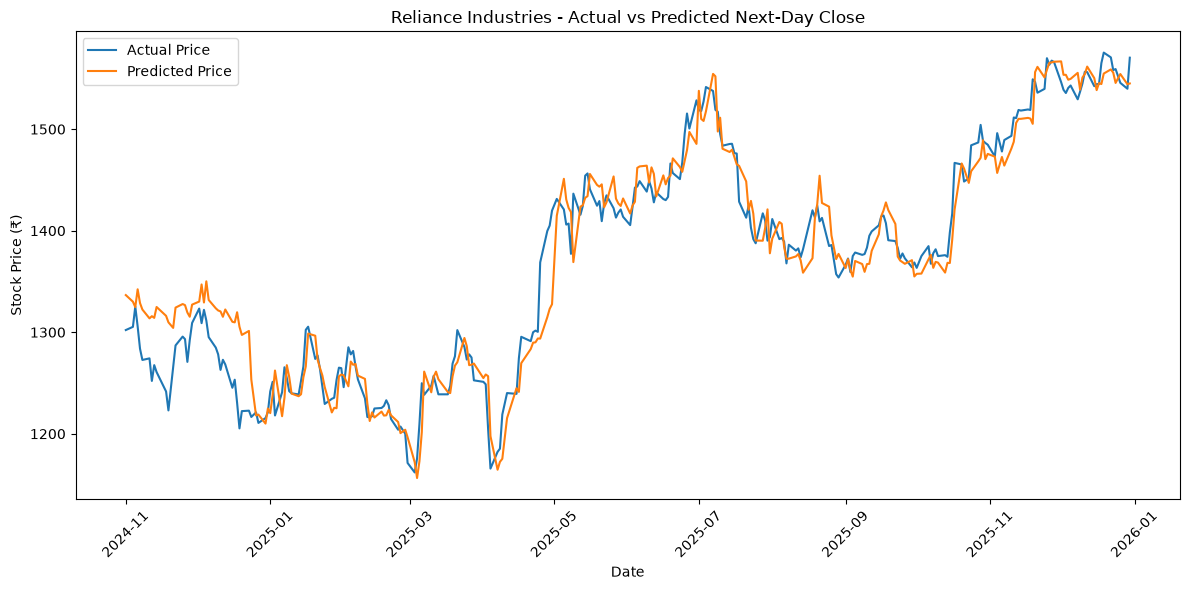

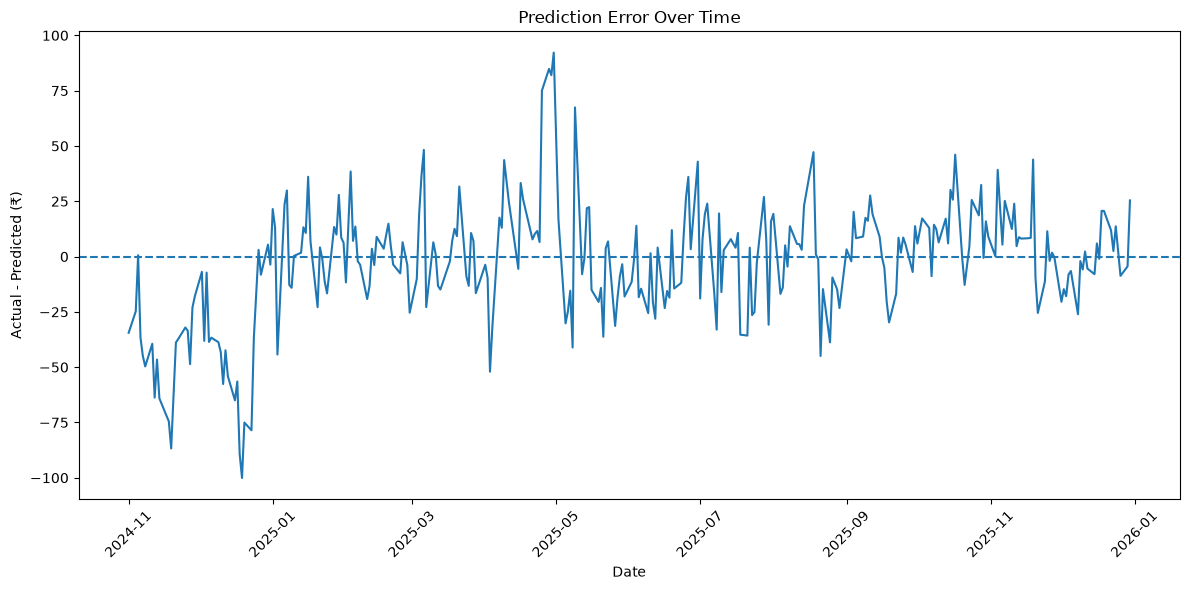

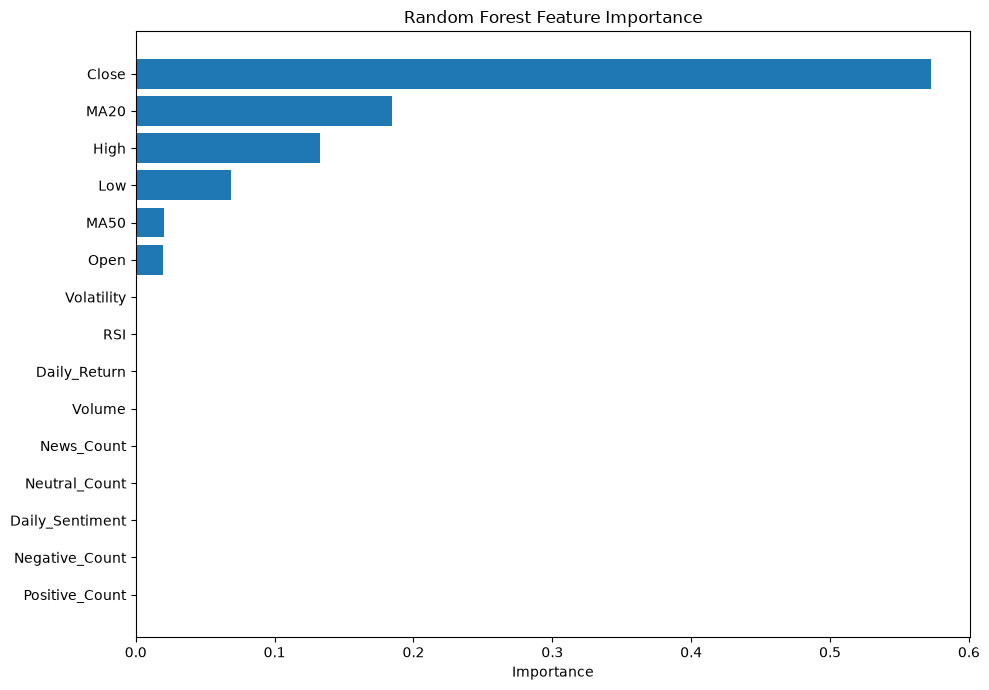

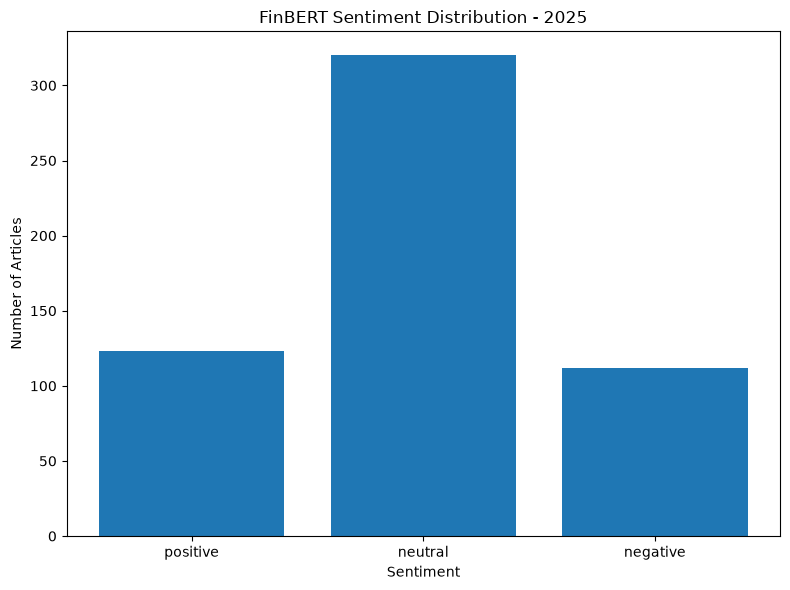

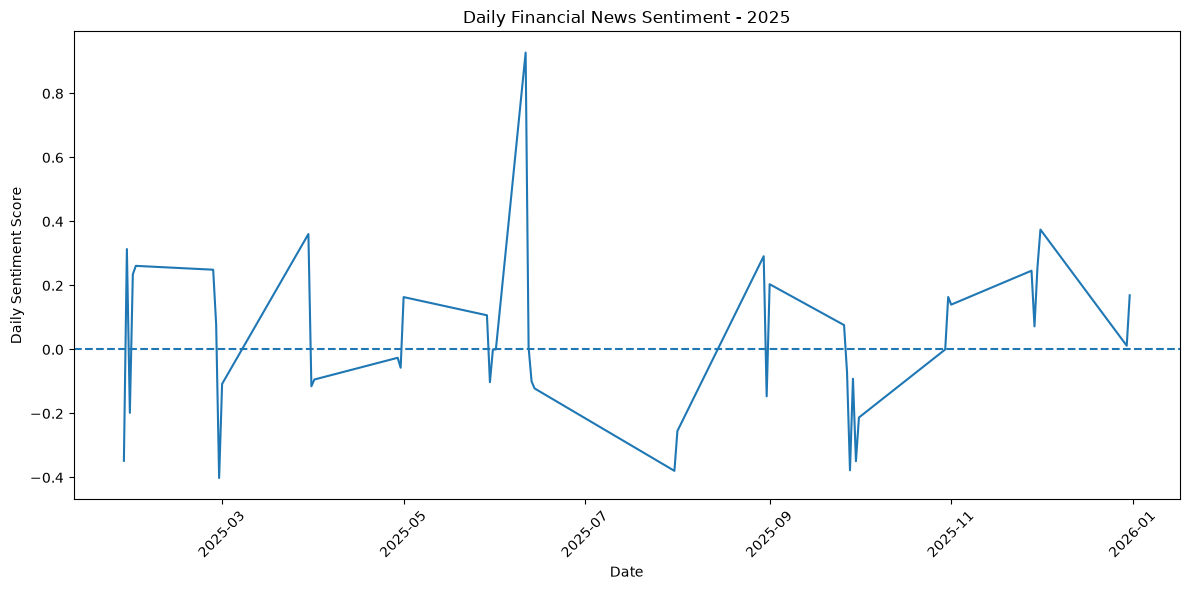

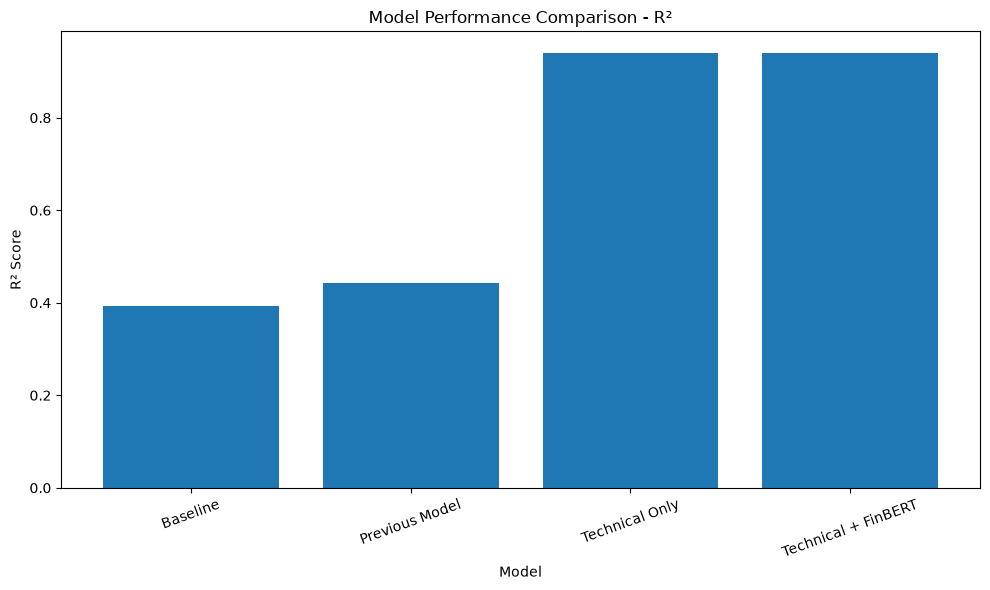


FINAL VISUALIZATION COMPLETE
Charts saved to:
D:\Projects\StockMarketSentimentPrediction\outputs\charts

Generated files:
✓ 01_actual_vs_predicted.png
✓ 02_prediction_error.png
✓ 03_feature_importance.png
✓ 04_sentiment_distribution.png
✓ 05_daily_sentiment_trend.png
✓ 06_model_performance_comparison.png
✓ reliance_historical_price.png

Prediction results saved to:
D:\Projects\StockMarketSentimentPrediction\dataset\processed\final_model_predictions.csv


In [21]:
# ============================================
# FINAL PROJECT VISUALIZATIONS
# Stock Market Sentiment + Price Prediction
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.ensemble import RandomForestRegressor

# ============================================
# PATHS
# ============================================

project_folder = Path(
    r"D:\Projects\StockMarketSentimentPrediction"
)

processed_folder = (
    project_folder / "dataset" / "processed"
)

news_folder = (
    project_folder / "dataset" / "news_data"
)

charts_folder = (
    project_folder / "outputs" / "charts"
)

charts_folder.mkdir(
    parents=True,
    exist_ok=True
)

# ============================================
# LOAD MODEL DATA
# ============================================

df = pd.read_csv(
    processed_folder /
    "reliance_model_dataset.csv"
)

df["Date"] = pd.to_datetime(df["Date"])

df = (
    df
    .sort_values("Date")
    .reset_index(drop=True)
)

# ============================================
# FEATURES
# ============================================

features = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Daily_Return",
    "MA20",
    "MA50",
    "Volatility",
    "RSI",
    "Daily_Sentiment",
    "News_Count",
    "Positive_Count",
    "Negative_Count",
    "Neutral_Count"
]

target = "Target_Next_Close"

X = df[features].copy()
y = df[target].copy()

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

X = X.fillna(
    X.median()
)

# ============================================
# SAME 80/20 CHRONOLOGICAL SPLIT
# ============================================

split_index = int(
    len(df) * 0.80
)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

test_dates = df["Date"].iloc[
    split_index:
].reset_index(drop=True)

# ============================================
# TRAIN FINAL MODEL
# ============================================

model = RandomForestRegressor(
    n_estimators=150,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train
)

y_pred = model.predict(
    X_test
)

# ============================================
# TEST RESULTS DATAFRAME
# ============================================

results = pd.DataFrame({
    "Date": test_dates,
    "Actual": y_test.reset_index(drop=True),
    "Predicted": y_pred
})

results["Error"] = (
    results["Actual"]
    - results["Predicted"]
)

results["Absolute_Error"] = (
    results["Error"].abs()
)

# ============================================
# 1. ACTUAL VS PREDICTED
# ============================================

plt.figure(figsize=(12, 6))

plt.plot(
    results["Date"],
    results["Actual"],
    label="Actual Price"
)

plt.plot(
    results["Date"],
    results["Predicted"],
    label="Predicted Price"
)

plt.title(
    "Reliance Industries - Actual vs Predicted Next-Day Close"
)

plt.xlabel("Date")
plt.ylabel("Stock Price (₹)")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    charts_folder /
    "01_actual_vs_predicted.png",
    dpi=300
)

plt.show()

# ============================================
# 2. RESIDUAL / ERROR PLOT
# ============================================

plt.figure(figsize=(12, 6))

plt.plot(
    results["Date"],
    results["Error"]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title(
    "Prediction Error Over Time"
)

plt.xlabel("Date")
plt.ylabel("Actual - Predicted (₹)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    charts_folder /
    "02_prediction_error.png",
    dpi=300
)

plt.show()

# ============================================
# 3. FEATURE IMPORTANCE
# ============================================

importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = (
    importance
    .sort_values(
        "Importance",
        ascending=True
    )
)

plt.figure(figsize=(10, 7))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.title(
    "Random Forest Feature Importance"
)

plt.xlabel("Importance")

plt.tight_layout()

plt.savefig(
    charts_folder /
    "03_feature_importance.png",
    dpi=300
)

plt.show()

# ============================================
# 4. SENTIMENT DISTRIBUTION
# ============================================

sentiment_file = (
    news_folder /
    "reliance_news_2025_sentiment.csv"
)

sentiment_df = pd.read_csv(
    sentiment_file
)

sentiment_counts = (
    sentiment_df["Sentiment"]
    .value_counts()
    .reindex(
        ["positive", "neutral", "negative"],
        fill_value=0
    )
)

plt.figure(figsize=(8, 6))

plt.bar(
    sentiment_counts.index,
    sentiment_counts.values
)

plt.title(
    "FinBERT Sentiment Distribution - 2025"
)

plt.xlabel("Sentiment")
plt.ylabel("Number of Articles")

plt.tight_layout()

plt.savefig(
    charts_folder /
    "04_sentiment_distribution.png",
    dpi=300
)

plt.show()

# ============================================
# 5. DAILY SENTIMENT TREND
# ============================================

daily_file = (
    news_folder /
    "reliance_daily_sentiment_2025.csv"
)

daily_sentiment = pd.read_csv(
    daily_file
)

daily_sentiment["Date"] = pd.to_datetime(
    daily_sentiment["Date"]
)

daily_sentiment = (
    daily_sentiment
    .sort_values("Date")
)

plt.figure(figsize=(12, 6))

plt.plot(
    daily_sentiment["Date"],
    daily_sentiment["Daily_Sentiment"]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title(
    "Daily Financial News Sentiment - 2025"
)

plt.xlabel("Date")
plt.ylabel("Daily Sentiment Score")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    charts_folder /
    "05_daily_sentiment_trend.png",
    dpi=300
)

plt.show()

# ============================================
# 6. MODEL PERFORMANCE COMPARISON
# ============================================

model_names = [
    "Baseline",
    "Previous Model",
    "Technical Only",
    "Technical + FinBERT"
]

r2_scores = [
    0.3923,
    0.4438,
    0.9393,
    0.9399
]

plt.figure(figsize=(10, 6))

plt.bar(
    model_names,
    r2_scores
)

plt.title(
    "Model Performance Comparison - R²"
)

plt.xlabel("Model")
plt.ylabel("R² Score")

plt.xticks(
    rotation=20
)

plt.tight_layout()

plt.savefig(
    charts_folder /
    "06_model_performance_comparison.png",
    dpi=300
)

plt.show()

# ============================================
# SAVE PREDICTIONS
# ============================================

prediction_file = (
    processed_folder /
    "final_model_predictions.csv"
)

results.to_csv(
    prediction_file,
    index=False
)

# ============================================
# FINAL SUMMARY
# ============================================

print("\n======================================")
print("FINAL VISUALIZATION COMPLETE")
print("======================================")

print(
    "Charts saved to:"
)

print(charts_folder)

print(
    "\nGenerated files:"
)

for file in sorted(charts_folder.glob("*.png")):
    print("✓", file.name)

print(
    "\nPrediction results saved to:"
)

print(prediction_file)